<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/LENGKAP_KODINGAN_KLP_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IMPORT LIBRARY

In [1]:
%pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 21.6 MB/s  0:00:00


In [2]:
# ============================================
# IMPORT LIBRARY ANALISIS GARCH
# ============================================

# Pengolahan data dan numerik
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt

# Analisis time series
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.arima.model import ARIMA

# Diagnostik residual
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

# Pemodelan GARCH
from arch import arch_model

# Evaluasi forecasting
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# Pengaturan tampilan
import warnings
warnings.filterwarnings("ignore")

Alur analisis GARCH:
1. Penyiapan data
   
   Mengurutkan data, menghitung log return, memeriksa missing value, dan membagi data training dan testing.
2. Pemeriksaan pola data
   
   Membuat plot deret waktu, mengamati fluktuasi, menguji stasioneritas ADF, serta melihat ACF dan PACF.
3. Identifikasi dan estimasi mean model
   
   Mengidentifikasi kandidat AR, MA, atau ARMA untuk memodelkan rata-rata bersyarat.
4. Evaluasi residual mean model
   
   Melakukan uji Ljung-Box dan ARCH-LM untuk memeriksa autokorelasi dan efek ARCH.
5. Estimasi model GARCH
   
   Mengestimasi beberapa kandidat orde GARCH dengan mean model yang telah ditentukan.
6. Pemilihan model dan pemeriksaan kompleksitas
   
   Membandingkan AIC, BIC, signifikansi parameter, persistensi volatilitas, dan konvergensi estimasi.
7. Diagnostik model GARCH
   
   Memeriksa residual terstandarisasi, kuadrat residual terstandarisasi, dan efek ARCH yang tersisa.
8. Forecasting
   
   Melakukan peramalan return dan volatilitas menggunakan model terpilih.
9. Evaluasi hasil forecasting
   
   Membandingkan hasil ramalan dengan data aktual menggunakan RMSE, MAE, dan MAPE jika target ramalannya adalah harga kurs.

In [3]:
# ============================================
# 1. PENYIAPAN DATA
# 1.1 LOAD DATA
# ============================================

url = (
    "https://raw.githubusercontent.com/"
    "fitridianamusa/Artikel-ADW-Kelompok-8/"
    "main/Data%20Historis%20USD_IDR.csv"
)

df = pd.read_csv(url, encoding="utf-8-sig")

print("Ukuran data:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi struktur data:")
df.info()

Ukuran data: (1442, 7)

Nama kolom:
['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.', 'Perubahan%']

Lima baris pertama:


,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
0,01/09/2026,"17.715,0","17.725,0","17.735,0","17.704,5",NaN,"0,00%"
1,31/08/2026,"17.715,0","17.750,0","17.770,0","17.712,5",NaN,"0,14%"
2,28/08/2026,"17.690,0","17.715,0","17.722,5","17.679,0",NaN,"-0,17%"
3,27/08/2026,"17.720,0","17.760,0","17.790,0","17.720,0",NaN,"0,11%"
4,26/08/2026,"17.700,0","17.695,0","17.733,5","17.677,5",NaN,"-0,06%"



Informasi struktur data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Tanggal     1442 non-null   object
 1   Terakhir    1442 non-null   object
 2   Pembukaan   1442 non-null   object
 3   Tertinggi   1442 non-null   object
 4   Terendah    1442 non-null   object
 5   Vol.        502 non-null    object
 6   Perubahan%  1442 non-null   object
dtypes: object(7)
memory usage: 79.0+ KB


In [4]:
# ============================================
# 1.2 PEMBERSIHAN DAN PENYIAPAN DATA
# ============================================

# Mengambil variabel yang dibutuhkan
data = df[["Tanggal", "Terakhir"]].copy()

# Mengubah format tanggal
data["Tanggal"] = pd.to_datetime(
    data["Tanggal"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Mengubah format harga kurs ke numerik
data["Terakhir"] = (
    data["Terakhir"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

data["Terakhir"] = pd.to_numeric(
    data["Terakhir"],
    errors="coerce"
)

# Mengurutkan data berdasarkan tanggal secara ascending
data = data.sort_values(
    by="Tanggal"
).reset_index(drop=True)

# Memeriksa missing value
print("Missing value:")
print(data.isnull().sum())

# Memeriksa duplikasi tanggal
print("\nJumlah tanggal duplikat:")
print(data["Tanggal"].duplicated().sum())

# Informasi data setelah pembersihan
print("\nUkuran data setelah pembersihan:", data.shape)

print("\nPeriode data:")
print(data["Tanggal"].min(), "sampai", data["Tanggal"].max())

print("\nTipe data:")
print(data.dtypes)

print("\nLima baris pertama:")
display(data.head())

print("\nLima baris terakhir:")
display(data.tail())

Missing value:
Tanggal     0
Terakhir    0
dtype: int64

Jumlah tanggal duplikat:
0

Ukuran data setelah pembersihan: (1442, 2)

Periode data:
2021-01-01 00:00:00 sampai 2026-09-01 00:00:00

Tipe data:
Tanggal     datetime64[ns]
Terakhir           float64
dtype: object

Lima baris pertama:


,Tanggal,Terakhir
0,2021-01-01,14213.7
1,2021-01-04,13885.0
2,2021-01-05,13900.0
3,2021-01-06,13880.0
4,2021-01-07,13890.0



Lima baris terakhir:


,Tanggal,Terakhir
1437,2026-08-26,17700.0
1438,2026-08-27,17720.0
1439,2026-08-28,17690.0
1440,2026-08-31,17715.0
1441,2026-09-01,17715.0


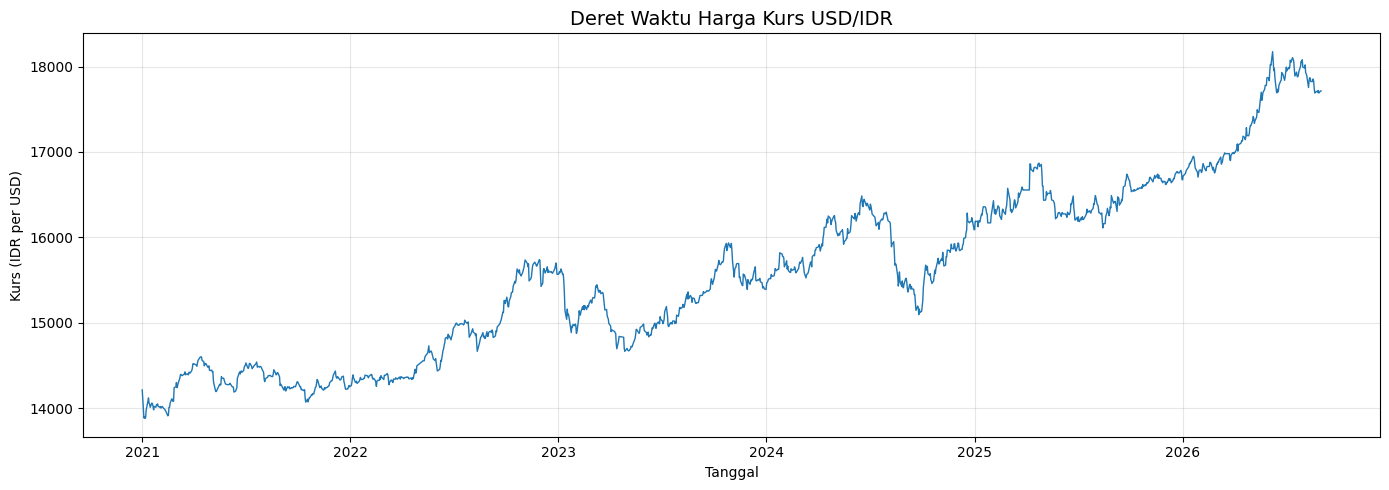

In [5]:
# ============================================
# 2. PEMERIKSAAN POLA DATA
# 2.1 VISUALISASI DERET WAKTU HARGA KURS
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    data["Tanggal"],
    data["Terakhir"],
    linewidth=1
)

plt.title("Deret Waktu Harga Kurs USD/IDR", fontsize=14)
plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# ============================================
# DEKOMPOSISI DATA KURS USD/IDR
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Mengurutkan data berdasarkan tanggal
data_dekomposisi = data.copy()

data_dekomposisi["Tanggal"] = pd.to_datetime(
    data_dekomposisi["Tanggal"]
)

data_dekomposisi = data_dekomposisi.sort_values(
    "Tanggal"
)

# Menjadikan tanggal sebagai index
data_dekomposisi = data_dekomposisi.set_index(
    "Tanggal"
)

# Mengambil variabel harga USD/IDR
kurs = data_dekomposisi["Terakhir"].dropna()

# Menampilkan data
display(kurs.head())

,Terakhir
Tanggal,
2021-01-01,14213.7
2021-01-04,13885.0
2021-01-05,13900.0
2021-01-06,13880.0
2021-01-07,13890.0


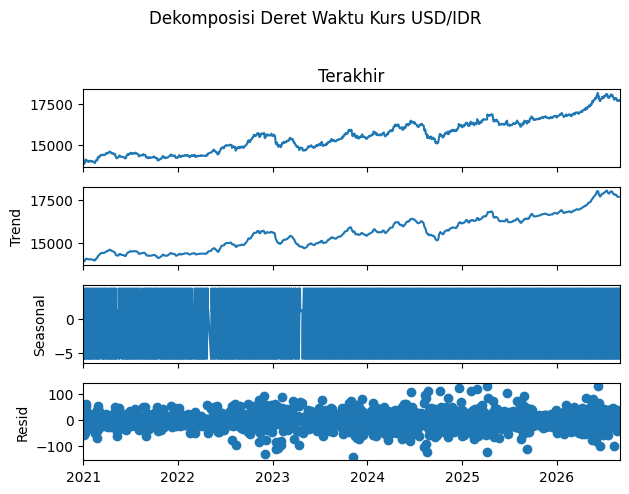

In [7]:
# ============================================
# DEKOMPOSISI ADDITIVE
# ============================================

result = seasonal_decompose(
    kurs,
    model="additive",
    period=5
)

# Menampilkan plot dekomposisi
result.plot()

plt.suptitle(
    "Dekomposisi Deret Waktu Kurs USD/IDR",
    y=1.02
)

plt.tight_layout()
plt.show()

In [8]:
# ============================================
# 2.2 STATISTIK DESKRIPTIF HARGA KURS
# ============================================

statistik_harga = data["Terakhir"].describe()

print("STATISTIK DESKRIPTIF HARGA KURS USD/IDR")
display(statistik_harga.to_frame().round(2))

STATISTIK DESKRIPTIF HARGA KURS USD/IDR


,Terakhir
count,1442.00
mean,15601.57
std,1024.34
min,13880.00
25%,14705.00
50%,15572.50
75%,16330.00
max,18175.00


In [9]:
# ============================================
# 2.3 TRANSFORMASI HARGA MENJADI LOG RETURN
# ============================================

# Membuat salinan data
data_return = data.copy()

# Menghitung log return dalam satuan persen
data_return["Log_Return"] = (
    100 * np.log(
        data_return["Terakhir"] /
        data_return["Terakhir"].shift(1)
    )
)

# Menghapus observasi pertama yang menghasilkan NA
data_return = data_return.dropna().reset_index(drop=True)

# Menampilkan hasil
print("Jumlah observasi setelah menghitung log return:",
      len(data_return))

print("\nLima baris pertama:")
display(data_return.head())

print("\nStatistik deskriptif log return:")
display(data_return["Log_Return"].describe().to_frame().round(6))

Jumlah observasi setelah menghitung log return: 1441

Lima baris pertama:


,Tanggal,Terakhir,Log_Return
0,2021-01-04,13885.0,-2.339717
1,2021-01-05,13900.0,0.107972
2,2021-01-06,13880.0,-0.143989
3,2021-01-07,13890.0,0.072020
4,2021-01-08,13980.0,0.645858



Statistik deskriptif log return:


,Log_Return
count,1441.000000
mean,0.015281
std,0.318211
min,-2.339717
25%,-0.123686
50%,0.000000
75%,0.189096
max,1.825578


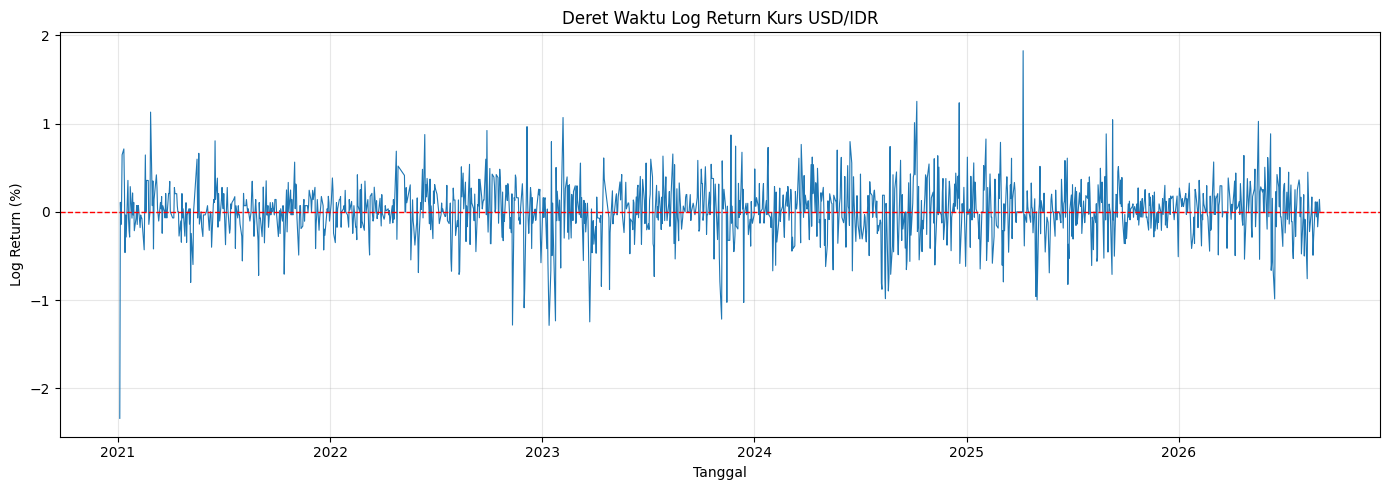

In [10]:
# ============================================
# 2.4 VISUALISASI LOG RETURN
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    data_return["Tanggal"],
    data_return["Log_Return"],
    linewidth=0.8
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.title("Deret Waktu Log Return Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Log Return (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# ============================================
# 2.5 UJI STASIONERITAS AUGMENTED DICKEY-FULLER
# ============================================

from statsmodels.tsa.stattools import adfuller

hasil_adf = adfuller(
    data_return["Log_Return"],
    autolag="AIC"
)

print("HASIL UJI AUGMENTED DICKEY-FULLER")
print("-----------------------------------")
print("ADF Statistic :", hasil_adf[0])
print("P-value       :", hasil_adf[1])
print("Lags Used     :", hasil_adf[2])
print("Observations  :", hasil_adf[3])

print("\nCritical Values:")
for key, value in hasil_adf[4].items():
    print(f"{key}: {value}")

if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Log return stasioner.")
else:
    print("\nKesimpulan: Log return belum stasioner.")

HASIL UJI AUGMENTED DICKEY-FULLER
-----------------------------------
ADF Statistic : -13.661078771248746
P-value       : 1.521020137874348e-25
Lags Used     : 6
Observations  : 1434

Critical Values:
1%: -3.434918371231736
5%: -2.8635576234668982
10%: -2.5678441693558898

Kesimpulan: Log return stasioner.


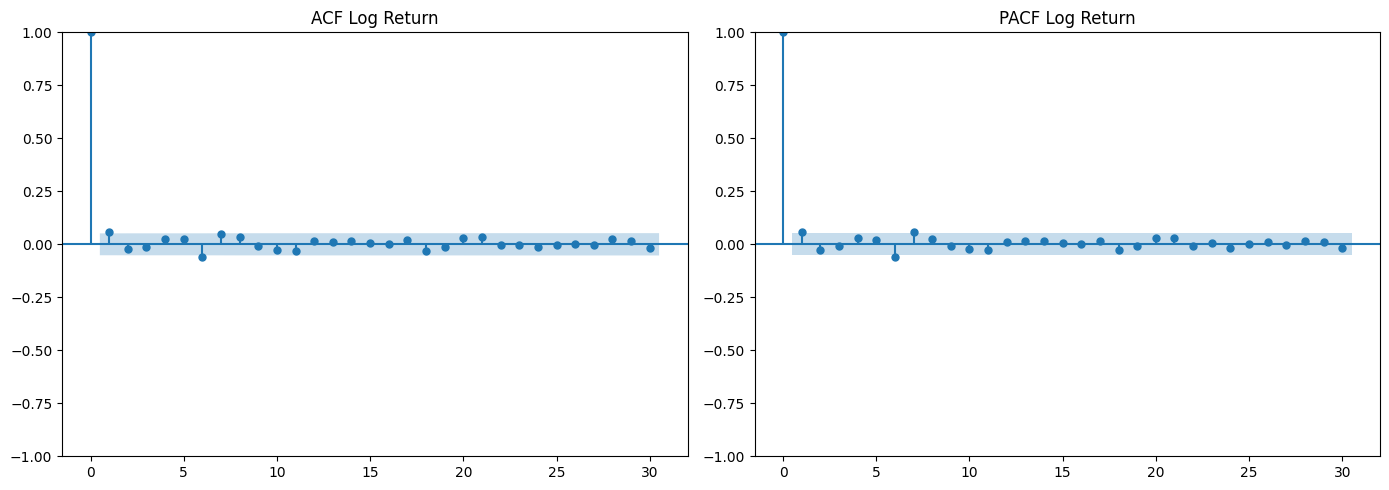

In [12]:
# ============================================
# 2.6 PLOT ACF DAN PACF LOG RETURN
# ============================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    data_return["Log_Return"],
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF Log Return")

plot_pacf(
    data_return["Log_Return"],
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF Log Return")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# 2.7 PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================

# Batas pembagian berdasarkan 1.400 observasi harga
batas_tanggal = data.iloc[1400]["Tanggal"]

# Membagi data log return berdasarkan tanggal
train = data_return[
    data_return["Tanggal"] < batas_tanggal
].copy()

test = data_return[
    data_return["Tanggal"] >= batas_tanggal
].copy()

# Memisahkan variabel log return
r_train = train["Log_Return"].copy()
r_test = test["Log_Return"].copy()

# Menampilkan hasil pembagian
print("Batas awal testing:", batas_tanggal)

print("\nJumlah observasi log return:")
print("Training:", len(train))
print("Testing :", len(test))

print("\nPeriode training:")
print(train["Tanggal"].min(), "sampai", train["Tanggal"].max())

print("\nPeriode testing:")
print(test["Tanggal"].min(), "sampai", test["Tanggal"].max())

Batas awal testing: 2026-07-06 00:00:00

Jumlah observasi log return:
Training: 1399
Testing : 42

Periode training:
2021-01-04 00:00:00 sampai 2026-07-03 00:00:00

Periode testing:
2026-07-06 00:00:00 sampai 2026-09-01 00:00:00


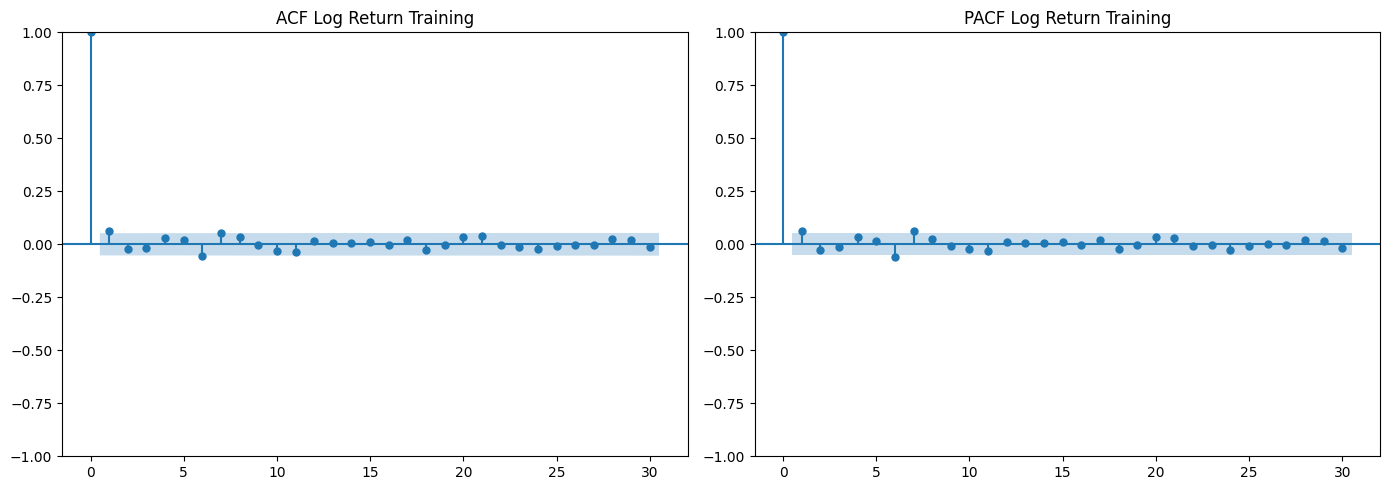

In [14]:
# ============================================
# ACF DAN PACF LOG RETURN TRAINING
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    r_train,
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF Log Return Training")

plot_pacf(
    r_train,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF Log Return Training")

plt.tight_layout()
plt.show()

In [15]:
# ============================================
# 3. IDENTIFIKASI DAN ESTIMASI MEAN MODEL
# ============================================

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

# Kandidat mean model
kandidat = {
    "AR(1)": (1, 0, 0),
    "MA(1)": (0, 0, 1),
    "ARMA(1,1)": (1, 0, 1)
}

# Menyimpan hasil estimasi
hasil_model = {}
hasil_perbandingan = []

for nama, orde in kandidat.items():

    model = ARIMA(
        r_train,
        order=orde
    )

    hasil = model.fit()

    hasil_model[nama] = hasil

    hasil_perbandingan.append({
        "Model": nama,
        "AIC": hasil.aic,
        "BIC": hasil.bic,
        "Log Likelihood": hasil.llf
    })

# Tabel perbandingan
tabel_model = pd.DataFrame(hasil_perbandingan)

print("HASIL PERBANDINGAN KANDIDAT MEAN MODEL")
display(tabel_model.round(5))

HASIL PERBANDINGAN KANDIDAT MEAN MODEL


,Model,AIC,BIC,Log Likelihood
0,AR(1),775.60576,791.33630,-384.80288
1,MA(1),775.32324,791.05378,-384.66162
2,"ARMA(1,1)",776.99170,797.96575,-384.49585


In [16]:
# ============================================
# HASIL ESTIMASI PARAMETER MEAN MODEL
# ============================================

for nama, hasil in hasil_model.items():

    print("\n" + "=" * 70)
    print(f"HASIL ESTIMASI {nama}")
    print("=" * 70)

    print(hasil.summary())


HASIL ESTIMASI AR(1)
                               SARIMAX Results                                
Dep. Variable:             Log_Return   No. Observations:                 1399
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -384.803
Date:                Mon, 09 Nov 2026   AIC                            775.606
Time:                        06:53:40   BIC                            791.336
Sample:                             0   HQIC                           781.486
                               - 1399                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0166      0.009      1.791      0.073      -0.002       0.035
ar.L1          0.0637      0.023      2.798      0.005       0.019       0.108
sigma2         0.1015      0.0

In [17]:
# ============================================
# 4. EVALUASI RESIDUAL MEAN MODEL
# ============================================

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

hasil_diagnostik = []

# Kandidat yang dipertahankan
kandidat_mean = ["AR(1)", "MA(1)"]

for nama in kandidat_mean:

    # Mengambil residual
    residual = hasil_model[nama].resid.dropna()

    # Uji Ljung-Box pada lag 10 dan 20
    lb = acorr_ljungbox(
        residual,
        lags=[10, 20],
        return_df=True
    )

    # Uji ARCH-LM dengan 10 lag
    arch_lm = het_arch(
        residual,
        nlags=10
    )

    hasil_diagnostik.append({
        "Model": nama,
        "LB Lag 10": lb.loc[10, "lb_pvalue"],
        "LB Lag 20": lb.loc[20, "lb_pvalue"],
        "ARCH-LM Statistic": arch_lm[0],
        "ARCH-LM P-value": arch_lm[1]
    })

# Membuat tabel hasil diagnostik
tabel_diagnostik = pd.DataFrame(hasil_diagnostik)

print("HASIL DIAGNOSTIK RESIDUAL MEAN MODEL")
display(tabel_diagnostik.round(5))

HASIL DIAGNOSTIK RESIDUAL MEAN MODEL


,Model,LB Lag 10,LB Lag 20,ARCH-LM Statistic,ARCH-LM P-value
0,AR(1),0.09244,0.33167,40.92274,0.00001
1,MA(1),0.10187,0.35112,40.76647,0.00001


In [18]:
# ============================================
# ACF DAN PACF RETURN KUADRAT
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

# Menghitung return kuadrat
return_kuadrat = pd.Series(
    np.asarray(r_train, dtype=float) ** 2,
    name="Squared_Log_Return"
)

print("Jumlah observasi:", len(return_kuadrat))
display(return_kuadrat.head())

Jumlah observasi: 1399


,Squared_Log_Return
0,5.474274
1,0.011658
2,0.020733
3,0.005187
4,0.417133


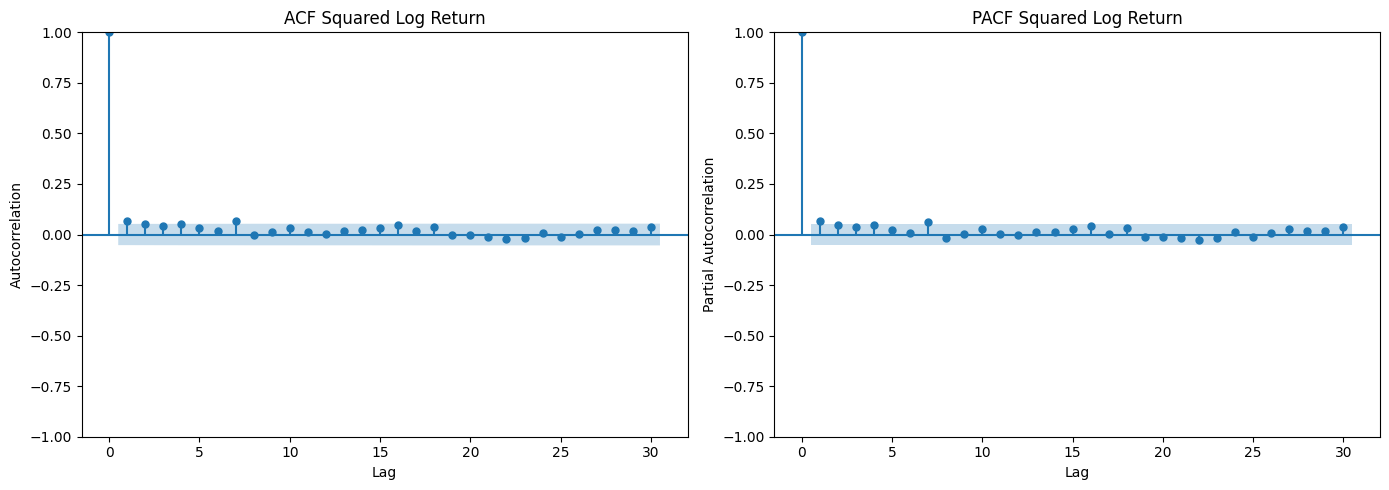

In [19]:
# ============================================
# PLOT ACF DAN PACF RETURN KUADRAT
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik ACF
plot_acf(
    return_kuadrat,
    lags=30,
    alpha=0.05,
    ax=axes[0]
)

axes[0].set_title("ACF Squared Log Return")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(False)


# Grafik PACF
plot_pacf(
    return_kuadrat,
    lags=30,
    alpha=0.05,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF Squared Log Return")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")
axes[1].grid(False)


plt.tight_layout()
plt.show()

In [20]:
# ============================================
# 5. ANALISIS GARCH
# AR(1)-GARCH(1,1)
# ============================================

from arch import arch_model

model_garch = arch_model(
    r_train,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=True
)

hasil_garch = model_garch.fit(disp="off")

print(hasil_garch.summary())

                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.004
Mean Model:                        AR   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -3532.96
Distribution:                  Normal   AIC:                           7075.91
Method:            Maximum Likelihood   BIC:                           7102.13
                                        No. Observations:                 1398
Date:                Mon, Nov 09 2026   Df Residuals:                     1396
Time:                        06:53:41   Df Model:                            2
                                  Mean Model                                 
                    coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------------------------------------
Const             0.1771  7.723e-02      2.294  2.181e-

In [21]:
# ============================================
# 5.2 PERBANDINGAN KANDIDAT MODEL GARCH
# Mean Model: AR(1)
# ============================================

kandidat_garch = {
    "GARCH(1,1)": (1, 1),
    "GARCH(1,2)": (1, 2),
    "GARCH(2,1)": (2, 1),
    "GARCH(2,2)": (2, 2)
}

hasil_garch_kandidat = {}
hasil_perbandingan = []

for nama, (p, q) in kandidat_garch.items():

    model = arch_model(
        r_train,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=p,
        q=q,
        dist="normal",
        rescale=True
    )

    hasil = model.fit(disp="off")

    hasil_garch_kandidat[nama] = hasil

    # Menghitung persistensi volatilitas
    alpha_sum = sum(
        hasil.params.get(f"alpha[{i}]", 0)
        for i in range(1, p + 1)
    )

    beta_sum = sum(
        hasil.params.get(f"beta[{i}]", 0)
        for i in range(1, q + 1)
    )

    hasil_perbandingan.append({
        "Model": nama,
        "AIC": hasil.aic,
        "BIC": hasil.bic,
        "Log Likelihood": hasil.loglikelihood,
        "Persistensi": alpha_sum + beta_sum,
        "Konvergensi": hasil.convergence_flag
    })

tabel_garch = pd.DataFrame(hasil_perbandingan)

print("PERBANDINGAN KANDIDAT MODEL GARCH")
display(tabel_garch.round(5))

PERBANDINGAN KANDIDAT MODEL GARCH


,Model,AIC,BIC,Log Likelihood,Persistensi,Konvergensi
0,"GARCH(1,1)",7075.91458,7102.12857,-3532.95729,0.99088,0
1,"GARCH(1,2)",7074.84844,7106.30523,-3531.42422,0.98646,0
2,"GARCH(2,1)",7077.91458,7109.37136,-3532.95729,0.99088,0
3,"GARCH(2,2)",7076.84844,7113.54803,-3531.42422,0.98646,0


In [22]:
# ============================================
# 5.3 PEMERIKSAAN SIGNIFIKANSI PARAMETER
# ============================================

for nama, hasil in hasil_garch_kandidat.items():

    print("\n" + "=" * 65)
    print(f"HASIL ESTIMASI {nama}")
    print("=" * 65)

    tabel_parameter = pd.DataFrame({
        "Koefisien": hasil.params,
        "P-value": hasil.pvalues
    })

    display(tabel_parameter.round(6))


HASIL ESTIMASI GARCH(1,1)


,Koefisien,P-value
Const,0.177130,0.021811
Log_Return[1],0.059568,0.038128
omega,0.097487,0.245677
alpha[1],0.034620,0.005944
beta[1],0.956256,0.000000



HASIL ESTIMASI GARCH(1,2)


,Koefisien,P-value
Const,0.189903,0.013707
Log_Return[1],0.055743,0.050112
omega,0.144607,0.219421
alpha[1],0.053392,0.001924
beta[1],0.377133,0.245098
beta[2],0.555936,0.084437



HASIL ESTIMASI GARCH(2,1)


,Koefisien,P-value
Const,0.177145,0.023414
Log_Return[1],0.059562,0.036019
omega,0.097487,0.260433
alpha[1],0.034618,0.144844
alpha[2],0.000000,1.000000
beta[1],0.956258,0.000000



HASIL ESTIMASI GARCH(2,2)


,Koefisien,P-value
Const,0.189909,0.013880
Log_Return[1],0.055742,0.049883
omega,0.144613,0.243078
alpha[1],0.053391,0.005200
alpha[2],0.000000,1.000000
beta[1],0.377156,0.357895
beta[2],0.555914,0.161415


In [23]:
# ============================================
# 6. DIAGNOSTIK MODEL AR(1)-GARCH(1,1)
# ============================================

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

# Mengambil model GARCH(1,1)
model_final_sementara = hasil_garch_kandidat["GARCH(1,1)"]

# Mengambil residual terstandarisasi
resid_std = model_final_sementara.std_resid.dropna()

# 1. Ljung-Box residual terstandarisasi
lb_resid = acorr_ljungbox(
    resid_std,
    lags=[10, 20],
    return_df=True
)

# 2. Ljung-Box kuadrat residual terstandarisasi
lb_resid_sq = acorr_ljungbox(
    resid_std**2,
    lags=[10, 20],
    return_df=True
)

# 3. ARCH-LM residual terstandarisasi
arch_test = het_arch(
    resid_std,
    nlags=10
)

# Membuat tabel hasil
hasil_diagnostik_garch = pd.DataFrame({
    "Pengujian": [
        "Ljung-Box Residual Lag 10",
        "Ljung-Box Residual Lag 20",
        "Ljung-Box Kuadrat Residual Lag 10",
        "Ljung-Box Kuadrat Residual Lag 20",
        "ARCH-LM"
    ],
    "Statistik": [
        lb_resid.loc[10, "lb_stat"],
        lb_resid.loc[20, "lb_stat"],
        lb_resid_sq.loc[10, "lb_stat"],
        lb_resid_sq.loc[20, "lb_stat"],
        arch_test[0]
    ],
    "P-value": [
        lb_resid.loc[10, "lb_pvalue"],
        lb_resid.loc[20, "lb_pvalue"],
        lb_resid_sq.loc[10, "lb_pvalue"],
        lb_resid_sq.loc[20, "lb_pvalue"],
        arch_test[1]
    ]
})

print("HASIL DIAGNOSTIK MODEL AR(1)-GARCH(1,1)")
display(hasil_diagnostik_garch.round(5))

HASIL DIAGNOSTIK MODEL AR(1)-GARCH(1,1)


,Pengujian,Statistik,P-value
0,Ljung-Box Residual Lag 10,16.44842,0.08750
1,Ljung-Box Residual Lag 20,21.87712,0.34722
2,Ljung-Box Kuadrat Residual Lag 10,10.52256,0.39590
3,Ljung-Box Kuadrat Residual Lag 20,13.63639,0.84844
4,ARCH-LM,10.68868,0.38228


In [24]:
# ============================================
# 8. FORECASTING AR(1)-GARCH(1,1)
# ROLLING ONE-STEP-AHEAD
# PERBAIKAN FAKTOR SKALA
# ============================================

# Mengambil model hasil estimasi training
model_final = hasil_garch_kandidat["GARCH(1,1)"]

# Mengambil parameter hasil estimasi
parameter_final = model_final.params

# Mengambil faktor skala model
scale = model_final.model.scale

print("Faktor skala model:", scale)

# Mengubah data ke skala yang sama dengan estimasi model
riwayat_return_scaled = r_train * scale

# Menyimpan hasil forecasting
prediksi_return = []
prediksi_varians = []

# Proses rolling one-step-ahead
for i in range(len(r_test)):

    # Membentuk model dengan data yang sudah diskalakan
    model_step = arch_model(
        riwayat_return_scaled,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    # Menggunakan parameter tetap hasil estimasi training
    hasil_step = model_step.fix(
        parameter_final.to_numpy()
    )

    # Forecast satu periode ke depan
    forecast_step = hasil_step.forecast(
        horizon=1,
        reindex=False
    )

    # Prediksi dalam skala estimasi
    return_scaled = forecast_step.mean.iloc[-1, 0]
    variance_scaled = forecast_step.variance.iloc[-1, 0]

    # Mengembalikan prediksi ke skala log return asli
    return_pred = return_scaled / scale
    variance_pred = variance_scaled / (scale ** 2)

    # Menyimpan hasil
    prediksi_return.append(return_pred)
    prediksi_varians.append(variance_pred)

    # Memasukkan observasi aktual setelah ramalan dibuat
    return_aktual_scaled = r_test.iloc[i] * scale

    riwayat_return_scaled = pd.concat([
        riwayat_return_scaled,
        pd.Series(
            [return_aktual_scaled],
            index=[r_test.index[i]]
        )
    ])

# Mengubah hasil menjadi array
prediksi_return = np.array(prediksi_return)
prediksi_varians = np.array(prediksi_varians)

# Menghitung volatilitas dalam skala asli
prediksi_volatilitas = np.sqrt(prediksi_varians)

print("\nFORECASTING SELESAI")
print("Jumlah ramalan:", len(prediksi_return))
print("Jumlah estimasi ulang parameter: 0")

print("\nRingkasan prediksi log return:")
print(pd.Series(prediksi_return).describe())

Faktor skala model: 10.0

FORECASTING SELESAI
Jumlah ramalan: 42
Jumlah estimasi ulang parameter: 0

Ringkasan prediksi log return:
count    42.000000
mean      0.015505
std       0.016679
min      -0.027408
25%       0.008056
50%       0.015390
75%       0.027699
max       0.044493
dtype: float64


In [25]:
# ============================================
# 8.2 KONVERSI PREDIKSI LOG RETURN KE HARGA
# ============================================

# Data aktual testing
harga_test = data.loc[
    data["Tanggal"] >= batas_tanggal,
    ["Tanggal", "Terakhir"]
].reset_index(drop=True)

# Harga terakhir training
harga_terakhir_train = data.loc[
    data["Tanggal"] < batas_tanggal,
    "Terakhir"
].iloc[-1]

# Harga aktual periode sebelumnya
harga_sebelumnya = np.concatenate([
    [harga_terakhir_train],
    harga_test["Terakhir"].iloc[:-1].to_numpy()
])

# Prediksi harga one-step-ahead
prediksi_harga = (
    harga_sebelumnya *
    np.exp(prediksi_return / 100)
)

# Tabel hasil forecasting
tabel_forecast = pd.DataFrame({
    "Tanggal": harga_test["Tanggal"],
    "Harga_Aktual": harga_test["Terakhir"],
    "Prediksi_Log_Return": prediksi_return,
    "Prediksi_Varians": prediksi_varians,
    "Prediksi_Volatilitas": prediksi_volatilitas,
    "Prediksi_Harga": prediksi_harga
})

print("HASIL FORECASTING ONE-STEP-AHEAD")
display(tabel_forecast.round(6))

HASIL FORECASTING ONE-STEP-AHEAD


,Tanggal,Harga_Aktual,Prediksi_Log_Return,Prediksi_Varians,Prediksi_Volatilitas,Prediksi_Harga
0,2026-07-06,17990.0,0.003460,0.132697,0.364276,17950.621162
1,2026-07-07,17975.0,0.030972,0.129530,0.359903,17995.572794
2,2026-07-08,17994.0,0.012744,0.125291,0.353965,17977.290926
3,2026-07-09,18075.0,0.024006,0.121084,0.347972,17998.320185
4,2026-07-10,18050.0,0.044467,0.123020,0.350742,18083.039234
5,2026-07-13,18105.0,0.009468,0.119771,0.346079,18051.709128
6,2026-07-14,18085.0,0.035836,0.118515,0.344260,18111.489310
7,2026-07-15,18065.0,0.011129,0.115047,0.339186,18087.012824
8,2026-07-16,17985.0,0.011122,0.111503,0.333920,18067.009282
9,2026-07-17,17890.0,-0.008725,0.114766,0.338771,17983.430925


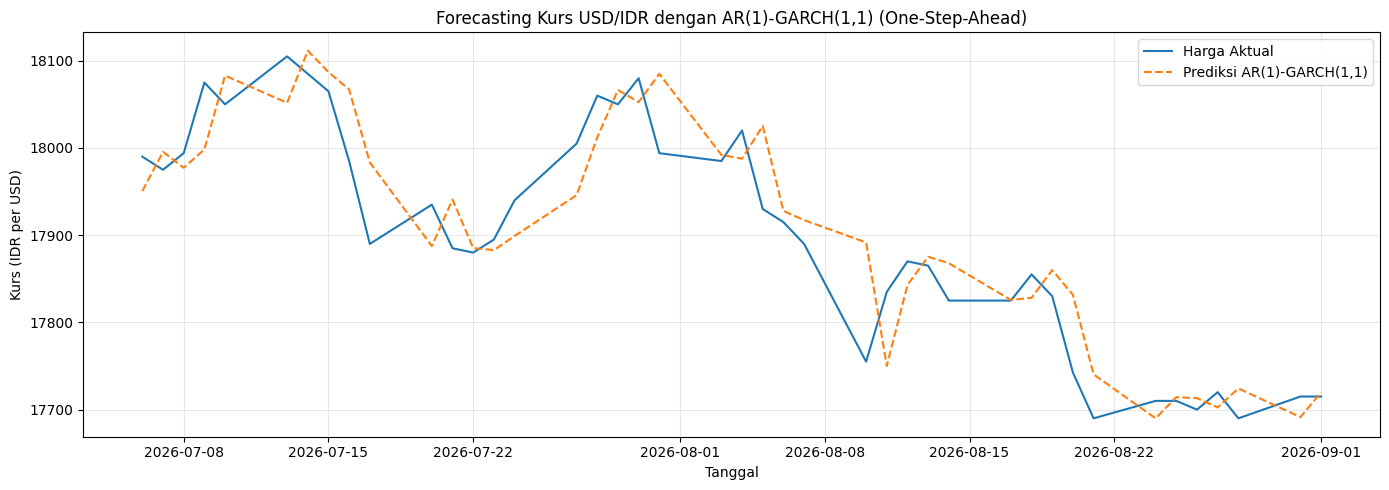

In [26]:
# ============================================
# 8.3 VISUALISASI HASIL FORECASTING
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    tabel_forecast["Tanggal"],
    tabel_forecast["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=1.5
)

plt.plot(
    tabel_forecast["Tanggal"],
    tabel_forecast["Prediksi_Harga"],
    label="Prediksi AR(1)-GARCH(1,1)",
    linestyle="--",
    linewidth=1.5
)

plt.title(
    "Forecasting Kurs USD/IDR dengan AR(1)-GARCH(1,1) "
    "(One-Step-Ahead)"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# ============================================
# 9. EVALUASI HASIL FORECASTING
# AR(1)-GARCH(1,1)
# ============================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# Mengambil nilai aktual dan prediksi harga
y_actual = tabel_forecast["Harga_Aktual"].to_numpy()
y_pred = tabel_forecast["Prediksi_Harga"].to_numpy()

# Menghitung metrik evaluasi
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
mape = mean_absolute_percentage_error(y_actual, y_pred) * 100

# Membuat tabel evaluasi
hasil_evaluasi = pd.DataFrame({
    "Model": ["AR(1)-GARCH(1,1)"],
    "RMSE": [rmse],
    "MAE": [mae],
    "MAPE (%)": [mape]
})

print("HASIL EVALUASI FORECASTING")
display(hasil_evaluasi.round(5))

HASIL EVALUASI FORECASTING


,Model,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",50.10417,39.48587,0.22053


# FORECASTING

In [28]:
# ============================================
# 10. ESTIMASI FINAL AR(1)-GARCH(1,1)
# MENGGUNAKAN SELURUH DATA AKTUAL
# ============================================

from arch import arch_model

r_all = data_return["Log_Return"].dropna()

model_final = arch_model(
    r_all,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=True
)

hasil_final = model_final.fit(disp="off")

print(hasil_final.summary())

print("\nJumlah observasi:", len(r_all))
print("Tanggal awal:", data_return["Tanggal"].min())
print("Tanggal akhir:", data_return["Tanggal"].max())
print("Faktor skala:", hasil_final.model.scale)

                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.004
Mean Model:                        AR   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -3637.00
Distribution:                  Normal   AIC:                           7283.99
Method:            Maximum Likelihood   BIC:                           7310.36
                                        No. Observations:                 1440
Date:                Mon, Nov 09 2026   Df Residuals:                     1438
Time:                        06:53:43   Df Model:                            2
                                  Mean Model                                 
                    coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------------------------------------
Const             0.1649  7.597e-02      2.170  2.997e-

Estimasi ulang ini dilakukan karena tahap evaluasi testing sudah selesai dan sekarang kita ingin menggunakan seluruh informasi aktual yang tersedia untuk memperoleh model final.

In [29]:
# ============================================
# 11. FORECASTING 7 PERIODE KE DEPAN
# RECURSIVE ONE-STEP-AHEAD
# AR(1)-GARCH(1,1)
# ============================================

# Menentukan horizon forecasting
horizon = 7

# Mengambil faktor skala model
scale = hasil_final.model.scale

# Forecast 7 langkah ke depan
forecast_final = hasil_final.forecast(
    horizon=horizon,
    reindex=False
)

# Mengambil prediksi mean dalam skala model
mean_scaled = forecast_final.mean.iloc[-1].to_numpy()

# Mengambil prediksi varians dalam skala model
variance_scaled = forecast_final.variance.iloc[-1].to_numpy()

# Mengembalikan ke skala log return asli
prediksi_return_future = mean_scaled / scale

prediksi_varians_future = (
    variance_scaled / (scale ** 2)
)

# Menghitung volatilitas
prediksi_volatilitas_future = np.sqrt(
    prediksi_varians_future
)

print("FORECASTING SELESAI")
print("Horizon:", horizon)
print("Faktor skala:", scale)

FORECASTING SELESAI
Horizon: 7
Faktor skala: 10.0


In [30]:
# ============================================
# 12. KONVERSI LOG RETURN KE HARGA KURS
# ============================================

# Mengambil harga aktual terakhir
harga_terakhir = data["Terakhir"].iloc[-1]

# Menghitung harga ramalan secara rekursif
prediksi_harga_future = (
    harga_terakhir *
    np.exp(np.cumsum(prediksi_return_future / 100))
)

# Membuat tanggal untuk 7 hari perdagangan
tanggal_terakhir = data["Tanggal"].iloc[-1]

tanggal_forecast = pd.bdate_range(
    start=tanggal_terakhir + pd.offsets.BDay(1),
    periods=horizon
)

# Membuat tabel hasil forecasting
tabel_forecast_future = pd.DataFrame({
    "Tanggal": tanggal_forecast,
    "Horizon": np.arange(1, horizon + 1),
    "Prediksi_Log_Return": prediksi_return_future,
    "Prediksi_Varians": prediksi_varians_future,
    "Prediksi_Volatilitas": prediksi_volatilitas_future,
    "Prediksi_Harga": prediksi_harga_future
})

print("HASIL FORECASTING 7 PERIODE KE DEPAN")
display(tabel_forecast_future.round(6))

HASIL FORECASTING 7 PERIODE KE DEPAN


,Tanggal,Horizon,Prediksi_Log_Return,Prediksi_Varians,Prediksi_Volatilitas,Prediksi_Harga
0,2026-09-02,1,0.016489,0.085005,0.291555,17717.921247
1,2026-09-03,2,0.017457,0.085465,0.292344,17721.014488
2,2026-09-04,3,0.017514,0.085633,0.292631,17724.118337
3,2026-09-07,4,0.017517,0.085798,0.292913,17727.223321
4,2026-09-08,5,0.017517,0.085961,0.293191,17730.328884
5,2026-09-09,6,0.017517,0.086123,0.293467,17733.434993
6,2026-09-10,7,0.017517,0.086283,0.293739,17736.541646


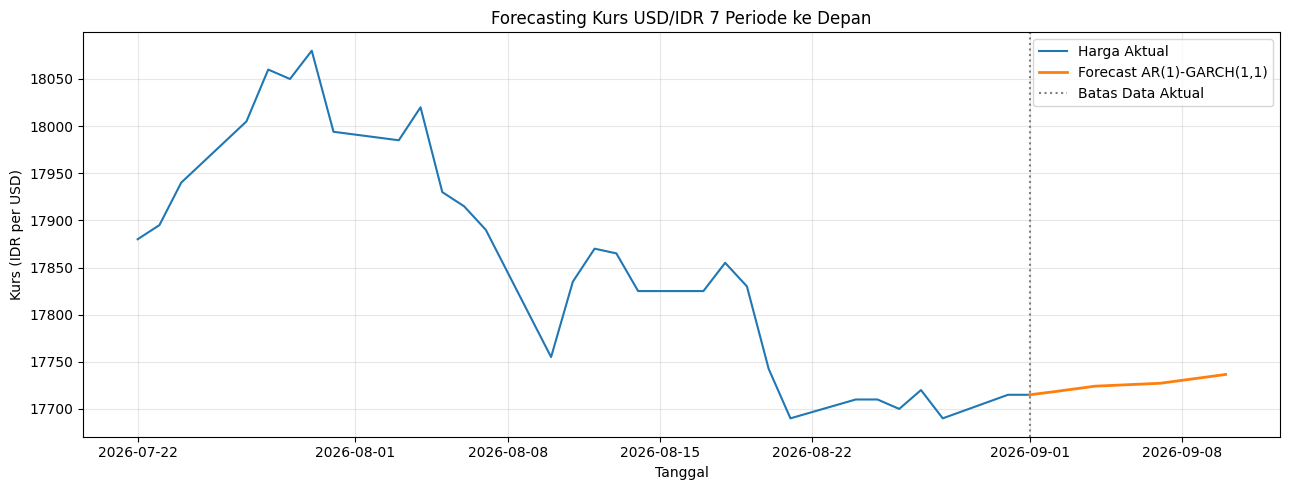

In [31]:
# ============================================
# 13. VISUALISASI FORECASTING 7 PERIODE
# ============================================

plt.figure(figsize=(13, 5))

# Data aktual: 30 observasi terakhir
data_plot = data.tail(30)

plt.plot(
    data_plot["Tanggal"],
    data_plot["Terakhir"],
    label="Harga Aktual",
    linewidth=1.5
)

# Menggabungkan tanggal dan harga aktual terakhir
# dengan hasil prediksi
tanggal_garis = pd.concat([
    pd.Series([tanggal_terakhir]),
    tabel_forecast_future["Tanggal"]
])

harga_garis = np.concatenate([
    [data["Terakhir"].iloc[-1]],
    tabel_forecast_future["Prediksi_Harga"].to_numpy()
])

# Garis prediksi masa mendatang
plt.plot(
    tanggal_garis,
    harga_garis,
    linestyle="-",
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=2
)

# Batas data aktual
plt.axvline(
    x=tanggal_terakhir,
    color="gray",
    linestyle=":",
    label="Batas Data Aktual"
)

plt.title(
    "Forecasting Kurs USD/IDR 7 Periode ke Depan"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **LSTM**

Tahapan analisis LSTM:
1. Persiapan data
   
   Menggunakan r_train dan r_test yang sudah dibentuk pada analisis GARCH.
2. Normalisasi data
   
   Menggunakan MinMaxScaler. Scaler hanya di-fit pada data training untuk mencegah kebocoran informasi (data leakage).
3. Pembentukan sekuens
   
   Menggunakan lookback 10, yaitu sepuluh observasi sebelumnya untuk memprediksi satu observasi berikutnya.
4. Pembentukan arsitektur LSTM
   
   Menentukan layer, unit, dropout, optimizer, dan fungsi loss.
5. Pelatihan model
   
   Melatih LSTM menggunakan data training dan memantau validation loss.
6. Prediksi data testing
   
   Melakukan rolling one-step-ahead dengan parameter model tetap. Nilai aktual testing baru dimasukkan setelah prediksi periode tersebut dihasilkan.
7. Konversi dan evaluasi
   
   Mengembalikan prediksi ke skala log return asli, mengubahnya menjadi harga kurs, lalu menghitung RMSE, MAE, dan MAPE.
8. Estimasi final dan forecasting
   
   Melatih ulang LSTM menggunakan seluruh 1.441 observasi aktual, kemudian melakukan forecasting tujuh periode ke depan secara rekursif.

In [32]:
# ============================================
# IMPORT LIBRARY UNTUK ANALISIS LSTM
# ============================================

# Pengolahan data
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Normalisasi data
from sklearn.preprocessing import MinMaxScaler

# Evaluasi model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# Arsitektur dan pelatihan LSTM
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Mengatur tampilan
plt.style.use("default")
sns.set_theme(style="whitegrid")

# Memeriksa versi TensorFlow
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)

# Memeriksa perangkat komputasi
print("\nPerangkat yang tersedia:")
print(tf.config.list_physical_devices())

NumPy version: 2.4.6
Pandas version: 2.2.3
TensorFlow version: 2.21.0

Perangkat yang tersedia:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [33]:
# ============================================
# 1. PERSIAPAN DATA UNTUK LSTM
# ============================================

# Mengambil kembali data training dan testing
# dari analisis GARCH

r_train_lstm = r_train.astype(float).copy()
r_test_lstm = r_test.astype(float).copy()

# Memeriksa jumlah observasi
print("JUMLAH OBSERVASI")
print("Training:", len(r_train_lstm))
print("Testing :", len(r_test_lstm))
print("Total   :", len(r_train_lstm) + len(r_test_lstm))

# Memeriksa missing value
print("\nMISSING VALUE")
print("Training:", r_train_lstm.isna().sum())
print("Testing :", r_test_lstm.isna().sum())

# Memeriksa tipe data
print("\nTIPE DATA")
print("Training:", r_train_lstm.dtype)
print("Testing :", r_test_lstm.dtype)

# Memeriksa periode data
print("\nPERIODE TRAINING")
print(train["Tanggal"].min(), "sampai", train["Tanggal"].max())

print("\nPERIODE TESTING")
print(test["Tanggal"].min(), "sampai", test["Tanggal"].max())

# Memeriksa nilai tidak valid
print("\nPEMERIKSAAN NILAI INFINITE")
print("Training:", np.isfinite(r_train_lstm).all())
print("Testing :", np.isfinite(r_test_lstm).all())

# Menampilkan lima observasi pertama
print("\nLIMA OBSERVASI TRAINING")
display(r_train_lstm.head())

print("\nLIMA OBSERVASI TESTING")
display(r_test_lstm.head())

JUMLAH OBSERVASI
Training: 1399
Testing : 42
Total   : 1441

MISSING VALUE
Training: 0
Testing : 0

TIPE DATA
Training: float64
Testing : float64

PERIODE TRAINING
2021-01-04 00:00:00 sampai 2026-07-03 00:00:00

PERIODE TESTING
2026-07-06 00:00:00 sampai 2026-09-01 00:00:00

PEMERIKSAAN NILAI INFINITE
Training: True
Testing : True

LIMA OBSERVASI TRAINING


,Log_Return
0,-2.339717
1,0.107972
2,-0.143989
3,0.072020
4,0.645858



LIMA OBSERVASI TESTING


,Log_Return
1399,0.222593
1400,-0.083414
1401,0.105647
1402,0.449140
1403,-0.138408


In [34]:
# ============================================
# 2. NORMALISASI DATA MENGGUNAKAN MINMAXSCALER
# ============================================

# Inisialisasi scaler
scaler_lstm = MinMaxScaler(feature_range=(0, 1))

# Mengubah data menjadi array 2 dimensi
train_values = r_train_lstm.to_numpy().reshape(-1, 1)
test_values = r_test_lstm.to_numpy().reshape(-1, 1)

# Fit scaler hanya pada data training
train_scaled = scaler_lstm.fit_transform(train_values)

# Transform data testing menggunakan scaler training
test_scaled = scaler_lstm.transform(test_values)

# Pemeriksaan hasil normalisasi
print("HASIL NORMALISASI DATA LSTM")

print("\nUkuran data:")
print("Training:", train_scaled.shape)
print("Testing :", test_scaled.shape)

print("\nNilai minimum dan maksimum:")
print("Training minimum:", train_scaled.min())
print("Training maksimum:", train_scaled.max())

print("Testing minimum:", test_scaled.min())
print("Testing maksimum:", test_scaled.max())

# Menampilkan lima observasi pertama
print("\nLIMA OBSERVASI TRAINING SETELAH NORMALISASI")
display(pd.DataFrame(
    train_scaled,
    columns=["Log_Return_Scaled"]
).head())

print("\nLIMA OBSERVASI TESTING SETELAH NORMALISASI")
display(pd.DataFrame(
    test_scaled,
    columns=["Log_Return_Scaled"]
).head())

HASIL NORMALISASI DATA LSTM

Ukuran data:
Training: (1399, 1)
Testing : (42, 1)

Nilai minimum dan maksimum:
Training minimum: 0.0
Training maksimum: 1.0
Testing minimum: 0.37986353207172485
Testing maksimum: 0.6696481407941416

LIMA OBSERVASI TRAINING SETELAH NORMALISASI


,Log_Return_Scaled
0,0.000000
1,0.587639
2,0.527148
3,0.579007
4,0.716774



LIMA OBSERVASI TESTING SETELAH NORMALISASI


,Log_Return_Scaled
0,0.615157
1,0.541691
2,0.587080
3,0.669546
4,0.528488


In [35]:
# ============================================
# 3. PEMBENTUKAN SEKUENS LSTM
# LOOKBACK = 10
# ============================================

# Menentukan panjang lookback
lookback = 10

# --------------------------------------------
# A. MEMBENTUK SEKUENS TRAINING
# --------------------------------------------

X_train_lstm = []
y_train_lstm = []

for i in range(lookback, len(train_scaled)):

    X_train_lstm.append(
        train_scaled[i-lookback:i, 0]
    )

    y_train_lstm.append(
        train_scaled[i, 0]
    )

# Mengubah ke array NumPy
X_train_lstm = np.array(X_train_lstm)
y_train_lstm = np.array(y_train_lstm)


# --------------------------------------------
# B. MEMBENTUK SEKUENS TESTING
# --------------------------------------------

# Menggabungkan 10 observasi terakhir training
# dengan seluruh observasi testing

test_input = np.concatenate([
    train_scaled[-lookback:],
    test_scaled
])

X_test_lstm = []
y_test_lstm = []

for i in range(lookback, len(test_input)):

    X_test_lstm.append(
        test_input[i-lookback:i, 0]
    )

    y_test_lstm.append(
        test_input[i, 0]
    )

# Mengubah ke array NumPy
X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)


# --------------------------------------------
# C. MENAMBAHKAN DIMENSI FITUR
# --------------------------------------------

X_train_lstm = X_train_lstm.reshape(
    X_train_lstm.shape[0],
    X_train_lstm.shape[1],
    1
)

X_test_lstm = X_test_lstm.reshape(
    X_test_lstm.shape[0],
    X_test_lstm.shape[1],
    1
)


# --------------------------------------------
# D. PEMERIKSAAN HASIL
# --------------------------------------------

print("HASIL PEMBENTUKAN SEKUENS LSTM")

print("\nParameter:")
print("Lookback:", lookback)

print("\nUkuran data:")
print("X_train:", X_train_lstm.shape)
print("y_train:", y_train_lstm.shape)
print("X_test :", X_test_lstm.shape)
print("y_test :", y_test_lstm.shape)

print("\nJumlah sekuens:")
print("Training:", len(X_train_lstm))
print("Testing :", len(X_test_lstm))

print("\nLima target pertama training:")
display(pd.DataFrame({
    "Target_Training": y_train_lstm[:5]
}))

print("\nLima target pertama testing:")
display(pd.DataFrame({
    "Target_Testing": y_test_lstm[:5]
}))

HASIL PEMBENTUKAN SEKUENS LSTM

Parameter:
Lookback: 10

Ukuran data:
X_train: (1389, 10, 1)
y_train: (1389,)
X_test : (42, 10, 1)
y_test : (42,)

Jumlah sekuens:
Training: 1389
Testing : 42

Lima target pertama training:


,Target_Training
0,0.647246
1,0.544636
2,0.510400
3,0.493123
4,0.630311



Lima target pertama testing:


,Target_Testing
0,0.615157
1,0.541691
2,0.587080
3,0.669546
4,0.528488


In [36]:
# ============================================
# 4. MEMBANGUN ARSITEKTUR LSTM
# ============================================

# Menetapkan seed
np.random.seed(42)
tf.random.set_seed(42)

# Membangun arsitektur LSTM
model_lstm = Sequential([
    tf.keras.Input(shape=(lookback, 1)),

    LSTM(
        units=50
    ),

    Dropout(
        rate=0.2
    ),

    Dense(
        units=1
    )
])

# Kompilasi model
model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

# Menampilkan ringkasan model
print("ARSITEKTUR MODEL LSTM")
model_lstm.summary()

ARSITEKTUR MODEL LSTM


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# ============================================
# 5. PELATIHAN MODEL LSTM
# ============================================

# Menetapkan seed
np.random.seed(42)
tf.random.set_seed(42)

# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Melatih model
history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

# Informasi hasil pelatihan
print("\nPELATIHAN LSTM SELESAI")

print("Epoch maksimum:", 100)
print("Epoch aktual:", len(history_lstm.history["loss"]))

print(
    "Training loss terbaik:",
    min(history_lstm.history["loss"])
)

print(
    "Validation loss terbaik:",
    min(history_lstm.history["val_loss"])
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0814 - val_loss: 0.0080
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0098 - val_loss: 0.0053
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0093 - val_loss: 0.0054
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0095 - val_loss: 0.0052
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0096 - val_loss: 0.0054
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0086 - val_loss: 0.0052
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0083 - val_loss: 0.0053
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0081 - val_loss: 0.0052
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0079 - val_loss: 0.0053
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0076 - val_loss: 0.0052
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0077 - val_loss: 0.0052
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0

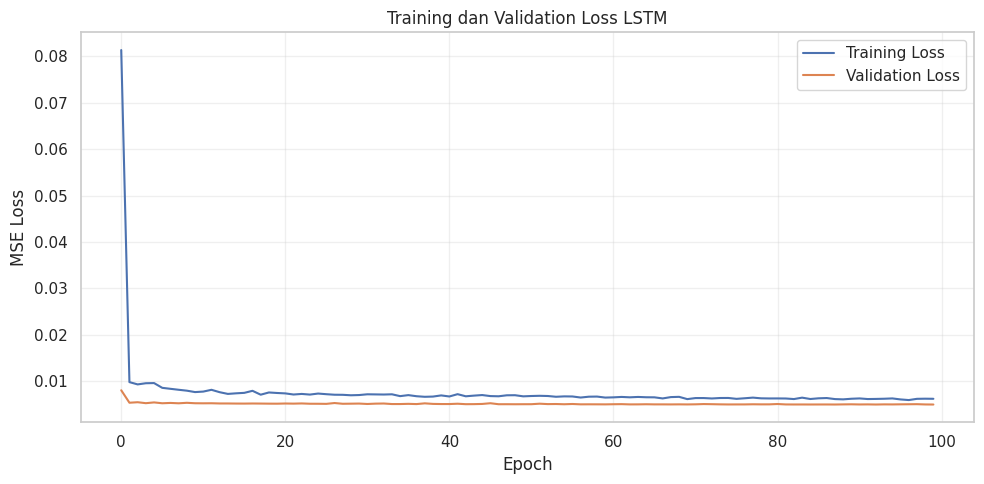

In [38]:
# ============================================
# 6. VISUALISASI TRAINING DAN VALIDATION LOSS
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training dan Validation Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# ============================================
# 6. PREDIKSI DATA TESTING MENGGUNAKAN LSTM
# ROLLING ONE-STEP-AHEAD
# ============================================

# Menghasilkan prediksi pada data testing
pred_scaled_lstm = model_lstm.predict(
    X_test_lstm,
    verbose=0
)

# Mengembalikan hasil normalisasi ke skala asli
pred_return_lstm = scaler_lstm.inverse_transform(
    pred_scaled_lstm
).flatten()

# Mengembalikan target testing ke skala asli
actual_return_lstm = scaler_lstm.inverse_transform(
    y_test_lstm.reshape(-1, 1)
).flatten()

print("PREDIKSI LSTM SELESAI")

print("Jumlah prediksi:", len(pred_return_lstm))

print("\nRingkasan prediksi log return:")
display(
    pd.Series(
        pred_return_lstm,
        name="Prediksi_Log_Return"
    ).describe()
)

PREDIKSI LSTM SELESAI
Jumlah prediksi: 42

Ringkasan prediksi log return:


,Prediksi_Log_Return
count,42.000000
mean,0.026936
std,0.016211
min,-0.015145
25%,0.016646
50%,0.024222
75%,0.039195
max,0.057201


In [40]:
# ============================================
# 7. KONVERSI PREDIKSI LOG RETURN KE HARGA
# ============================================

# Harga aktual testing
harga_aktual_lstm = test["Terakhir"].to_numpy()

# Harga aktual terakhir training
harga_terakhir_train = train["Terakhir"].iloc[-1]

# Membentuk harga aktual periode sebelumnya
harga_sebelumnya_lstm = np.concatenate([
    [harga_terakhir_train],
    harga_aktual_lstm[:-1]
])

# Menghitung harga prediksi
pred_harga_lstm = (
    harga_sebelumnya_lstm *
    np.exp(pred_return_lstm / 100)
)

# Membuat tabel hasil prediksi
hasil_lstm = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Harga_Aktual": harga_aktual_lstm,
    "Aktual_Log_Return": actual_return_lstm,
    "Prediksi_Log_Return": pred_return_lstm,
    "Prediksi_Harga": pred_harga_lstm
})

print("HASIL PREDIKSI LSTM PADA DATA TESTING")
display(hasil_lstm.round(6))

HASIL PREDIKSI LSTM PADA DATA TESTING


,Tanggal,Harga_Aktual,Aktual_Log_Return,Prediksi_Log_Return,Prediksi_Harga
0,2026-07-06,17990.0,0.222593,0.038833,17956.973630
1,2026-07-07,17975.0,-0.083414,0.047290,17998.511819
2,2026-07-08,17994.0,0.105647,0.039316,17982.069054
3,2026-07-09,18075.0,0.449140,0.041745,18001.514117
4,2026-07-10,18050.0,-0.138408,0.057201,18085.342598
5,2026-07-13,18105.0,0.304246,0.044252,18057.989365
6,2026-07-14,18085.0,-0.110528,0.055458,18115.042496
7,2026-07-15,18065.0,-0.110650,0.043876,18092.938024
8,2026-07-16,17985.0,-0.443829,0.037074,18071.697434
9,2026-07-17,17890.0,-0.529618,0.017937,17988.226689


In [41]:
# ============================================
# 8. EVALUASI MODEL LSTM
# ============================================

rmse_lstm = np.sqrt(
    mean_squared_error(
        hasil_lstm["Harga_Aktual"],
        hasil_lstm["Prediksi_Harga"]
    )
)

mae_lstm = mean_absolute_error(
    hasil_lstm["Harga_Aktual"],
    hasil_lstm["Prediksi_Harga"]
)

mape_lstm = (
    mean_absolute_percentage_error(
        hasil_lstm["Harga_Aktual"],
        hasil_lstm["Prediksi_Harga"]
    ) * 100
)

evaluasi_lstm = pd.DataFrame({
    "Model": ["LSTM"],
    "RMSE": [rmse_lstm],
    "MAE": [mae_lstm],
    "MAPE (%)": [mape_lstm]
})

print("HASIL EVALUASI FORECASTING LSTM")
display(evaluasi_lstm.round(5))

HASIL EVALUASI FORECASTING LSTM


,Model,RMSE,MAE,MAPE (%)
0,LSTM,50.68737,40.02068,0.22353


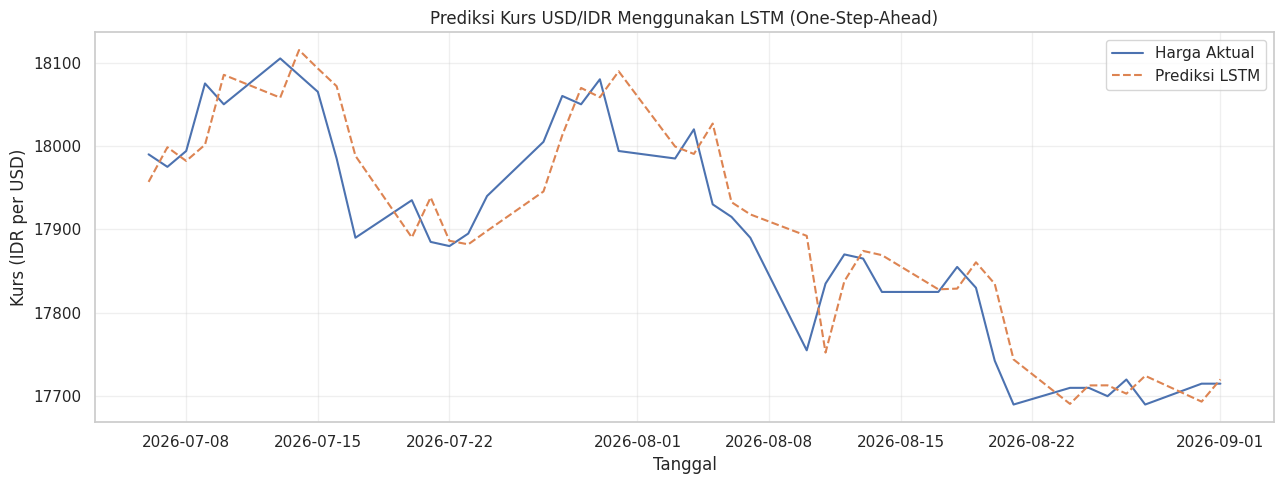

In [42]:
# ============================================
# 9. VISUALISASI PREDIKSI LSTM
# ============================================

plt.figure(figsize=(13, 5))

plt.plot(
    hasil_lstm["Tanggal"],
    hasil_lstm["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=1.5
)

plt.plot(
    hasil_lstm["Tanggal"],
    hasil_lstm["Prediksi_Harga"],
    linestyle="--",
    label="Prediksi LSTM",
    linewidth=1.5
)

plt.title(
    "Prediksi Kurs USD/IDR Menggunakan LSTM (One-Step-Ahead)"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# ============================================
# 10. PERSIAPAN DATA FINAL UNTUK FORECASTING
# LSTM TUNGGAL
# ============================================

# Mengambil seluruh data log return
r_all_lstm = data_return["Log_Return"].astype(float).copy()

# Mengubah menjadi array
all_values_lstm = r_all_lstm.to_numpy().reshape(-1, 1)

# Normalisasi menggunakan seluruh data aktual
scaler_lstm_final = MinMaxScaler(feature_range=(0, 1))

all_scaled_lstm = scaler_lstm_final.fit_transform(
    all_values_lstm
)

print("PERSIAPAN DATA FINAL LSTM")

print("Jumlah observasi:", len(all_values_lstm))
print("Tanggal awal:", data_return["Tanggal"].min())
print("Tanggal akhir:", data_return["Tanggal"].max())

print("Ukuran data:", all_scaled_lstm.shape)

print("Minimum:", all_scaled_lstm.min())
print("Maksimum:", all_scaled_lstm.max())

PERSIAPAN DATA FINAL LSTM
Jumlah observasi: 1441
Tanggal awal: 2021-01-04 00:00:00
Tanggal akhir: 2026-09-01 00:00:00
Ukuran data: (1441, 1)
Minimum: 0.0
Maksimum: 1.0


In [44]:
# ============================================
# 11. PEMBENTUKAN SEKUENS DATA FINAL
# ============================================

X_all_lstm = []
y_all_lstm = []

for i in range(lookback, len(all_scaled_lstm)):

    X_all_lstm.append(
        all_scaled_lstm[i-lookback:i, 0]
    )

    y_all_lstm.append(
        all_scaled_lstm[i, 0]
    )

X_all_lstm = np.array(X_all_lstm)
y_all_lstm = np.array(y_all_lstm)

# Menambahkan dimensi fitur
X_all_lstm = X_all_lstm.reshape(
    X_all_lstm.shape[0],
    X_all_lstm.shape[1],
    1
)

print("SEKUENS FINAL LSTM")

print("X_all:", X_all_lstm.shape)
print("y_all:", y_all_lstm.shape)

SEKUENS FINAL LSTM
X_all: (1431, 10, 1)
y_all: (1431,)


In [45]:
# ============================================
# 12. ESTIMASI FINAL MODEL LSTM
# ============================================

# Menentukan epoch terbaik dari pelatihan sebelumnya
best_epoch_lstm = (
    np.argmin(history_lstm.history["val_loss"]) + 1
)

print("Epoch terbaik:", best_epoch_lstm)

# Mengatur seed
np.random.seed(42)
tf.random.set_seed(42)

# Membangun ulang model final
model_lstm_final = Sequential([
    tf.keras.Input(shape=(lookback, 1)),

    LSTM(units=50),

    Dropout(rate=0.2),

    Dense(units=1)
])

# Kompilasi
model_lstm_final.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

# Pelatihan menggunakan seluruh data
history_lstm_final = model_lstm_final.fit(
    X_all_lstm,
    y_all_lstm,
    epochs=best_epoch_lstm,
    batch_size=32,
    shuffle=False,
    verbose=1
)

print("\nESTIMASI FINAL LSTM SELESAI")
print("Jumlah observasi:", len(r_all_lstm))
print("Jumlah sekuens:", len(X_all_lstm))
print("Epoch pelatihan:", best_epoch_lstm)

Epoch terbaik: 100
Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0558
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0089
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0081
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0084
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0080
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0077
Epoch 8/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0077
Epoch 9/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0075
Epoch 10/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0078
Epoch 11/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0073
Epoch 12/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0073
Epoch 13/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0074
Epoch 14/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0072
Epoch 15/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

In [46]:
# ============================================
# 13. FORECASTING 7 PERIODE KE DEPAN
# RECURSIVE LSTM
# ============================================

# Menentukan horizon forecasting
horizon = 7

# Mengambil 10 observasi terakhir sebagai input awal
last_sequence_lstm = all_scaled_lstm[-lookback:].reshape(
    1, lookback, 1
)

# Menampung hasil prediksi
pred_scaled_future_lstm = []

# Proses forecasting rekursif
for i in range(horizon):

    # Prediksi satu langkah ke depan
    pred_scaled = model_lstm_final.predict(
        last_sequence_lstm,
        verbose=0
    )

    # Menyimpan prediksi
    pred_scaled_future_lstm.append(
        pred_scaled[0, 0]
    )

    # Memperbarui sekuens menggunakan hasil prediksi
    last_sequence_lstm = np.concatenate(
        [
            last_sequence_lstm[:, 1:, :],
            pred_scaled.reshape(1, 1, 1)
        ],
        axis=1
    )

# Mengembalikan prediksi ke skala log return asli
pred_return_future_lstm = scaler_lstm_final.inverse_transform(
    np.array(pred_scaled_future_lstm).reshape(-1, 1)
).flatten()

print("FORECASTING LSTM SELESAI")
print("Horizon:", horizon)
print("Jumlah ramalan:", len(pred_return_future_lstm))

print("\nRingkasan prediksi log return:")
display(
    pd.Series(
        pred_return_future_lstm,
        name="Prediksi_Log_Return"
    ).describe()
)

FORECASTING LSTM SELESAI
Horizon: 7
Jumlah ramalan: 7

Ringkasan prediksi log return:


,Prediksi_Log_Return
count,7.000000
mean,0.025079
std,0.001489
min,0.022222
25%,0.024580
50%,0.025808
75%,0.026031
max,0.026303


In [47]:
# ============================================
# 14. KONVERSI PREDIKSI LOG RETURN KE HARGA
# ============================================

# Harga aktual terakhir
harga_terakhir_lstm = data["Terakhir"].iloc[-1]

# Menghitung harga prediksi secara kumulatif
pred_harga_future_lstm = (
    harga_terakhir_lstm *
    np.exp(np.cumsum(pred_return_future_lstm / 100))
)

# Tanggal terakhir data aktual
tanggal_terakhir_lstm = pd.to_datetime(
    data["Tanggal"].iloc[-1]
)

# Membentuk 7 tanggal perdagangan
tanggal_forecast_lstm = pd.bdate_range(
    start=tanggal_terakhir_lstm + pd.offsets.BDay(1),
    periods=horizon
)

# Membuat tabel hasil forecasting
hasil_forecast_lstm = pd.DataFrame({
    "Tanggal": tanggal_forecast_lstm,
    "Horizon": np.arange(1, horizon + 1),
    "Prediksi_Log_Return": pred_return_future_lstm,
    "Prediksi_Harga": pred_harga_future_lstm
})

print("HASIL FORECASTING LSTM 7 PERIODE KE DEPAN")
display(hasil_forecast_lstm.round(6))

HASIL FORECASTING LSTM 7 PERIODE KE DEPAN


,Tanggal,Horizon,Prediksi_Log_Return,Prediksi_Harga
0,2026-09-02,1,0.022222,17718.936381
1,2026-09-03,2,0.023954,17723.181084
2,2026-09-04,3,0.025206,17727.649637
3,2026-09-07,4,0.025808,17732.225892
4,2026-09-08,5,0.025930,17736.823264
5,2026-09-09,6,0.026132,17741.458649
6,2026-09-10,7,0.026303,17746.125711


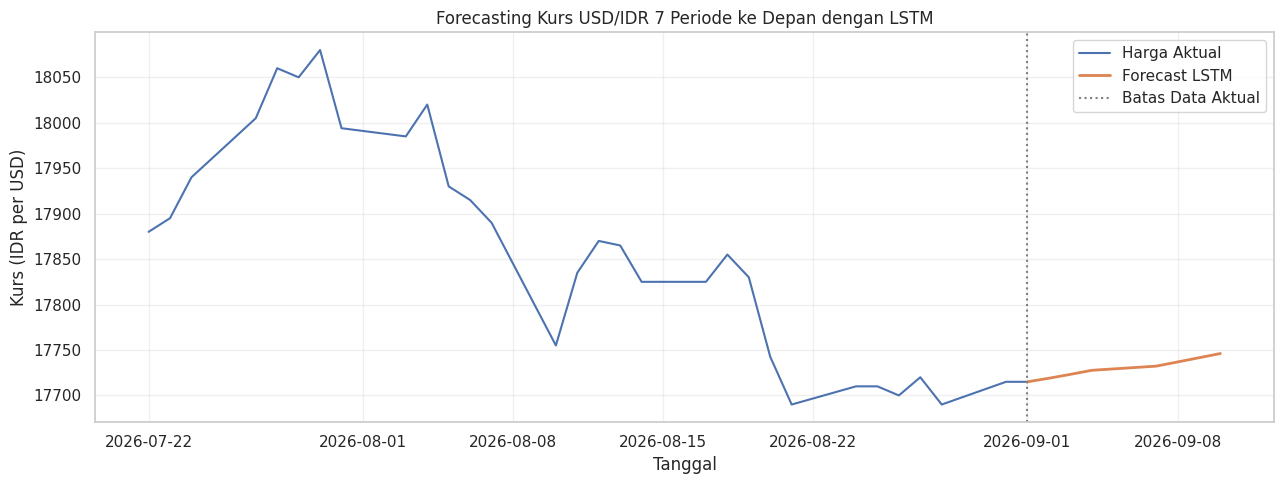

In [48]:
# ============================================
# 15. VISUALISASI FORECASTING LSTM
# ============================================

plt.figure(figsize=(13, 5))

# Menampilkan 30 observasi aktual terakhir
data_plot_lstm = data.tail(30)

plt.plot(
    data_plot_lstm["Tanggal"],
    data_plot_lstm["Terakhir"],
    label="Harga Aktual",
    linewidth=1.5
)

# Menggabungkan titik terakhir aktual dengan hasil ramalan
tanggal_garis_lstm = pd.concat([
    pd.Series([tanggal_terakhir_lstm]),
    hasil_forecast_lstm["Tanggal"]
])

harga_garis_lstm = np.concatenate([
    [harga_terakhir_lstm],
    hasil_forecast_lstm["Prediksi_Harga"].to_numpy()
])

# Menampilkan ramalan sebagai garis utuh tanpa titik
plt.plot(
    tanggal_garis_lstm,
    harga_garis_lstm,
    linestyle="-",
    linewidth=2,
    label="Forecast LSTM"
)

# Batas data aktual
plt.axvline(
    x=tanggal_terakhir_lstm,
    color="gray",
    linestyle=":",
    label="Batas Data Aktual"
)

plt.title("Forecasting Kurs USD/IDR 7 Periode ke Depan dengan LSTM")
plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **HYBRID GARCH-LSTM**

Tahapan Analisis Hybrid GARCH-LSTM:

1. Estimasi AR(1)-GARCH(1,1) pada data training.
2. Menghitung residual GARCH.
3. Normalisasi residual.
4. Pembentukan sekuens residual.
5. Menentukan arsitektur LSTM residual.
6. Melatih dan memvalidasi LSTM.
7. Prediksi data testing secara one-step-ahead.
8. Menggabungkan prediksi GARCH dan LSTM.
9. Konversi prediksi log return menjadi harga.
10. Evaluasi dan visualisasi.
11. Forecasting 7 periode ke depan.

In [49]:
# ============================================
# 1. ESTIMASI AR(1)-GARCH(1,1)
# UNTUK MODEL HYBRID
# ============================================

# Faktor skala yang sama dengan analisis GARCH
scale_factor_hybrid = 10.0

# Mengambil data training
r_train_hybrid = r_train.astype(float).copy()

# Mengalikan log return dengan faktor skala
r_train_scaled_hybrid = (
    r_train_hybrid * scale_factor_hybrid
)

# Membentuk model AR(1)-GARCH(1,1)
model_garch_hybrid = arch_model(
    r_train_scaled_hybrid,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)

# Estimasi parameter
hasil_garch_hybrid = model_garch_hybrid.fit(
    disp="off"
)

# Menampilkan hasil estimasi
print("HASIL ESTIMASI AR(1)-GARCH(1,1)")
print(hasil_garch_hybrid.summary())

HASIL ESTIMASI AR(1)-GARCH(1,1)
                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.004
Mean Model:                        AR   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -3532.96
Distribution:                  Normal   AIC:                           7075.91
Method:            Maximum Likelihood   BIC:                           7102.13
                                        No. Observations:                 1398
Date:                Mon, Nov 09 2026   Df Residuals:                     1396
Time:                        06:55:11   Df Model:                            2
                                  Mean Model                                 
                    coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------------------------------------
Const             0.177

In [50]:
# ============================================
# 2. EKSTRAKSI RESIDUAL GARCH
# ============================================

# Mengambil residual GARCH
resid_train_hybrid = pd.Series(
    hasil_garch_hybrid.resid,
    index=r_train_hybrid.index
)

# Mengembalikan residual ke skala log return asli
resid_train_hybrid = (
    resid_train_hybrid / scale_factor_hybrid
)

# Menghapus nilai awal yang tidak tersedia
resid_train_hybrid = resid_train_hybrid.dropna()

# Menampilkan hasil
print("HASIL EKSTRAKSI RESIDUAL GARCH")

print("\nJumlah residual:", len(resid_train_hybrid))

print("\nStatistik deskriptif residual:")
display(resid_train_hybrid.describe())

print("\nLima residual pertama:")
display(resid_train_hybrid.head())

print("\nLima residual terakhir:")
display(resid_train_hybrid.tail())

HASIL EKSTRAKSI RESIDUAL GARCH

Jumlah residual: 1398

Statistik deskriptif residual:


,resid
count,1398.000000
mean,-0.000350
std,0.312532
min,-1.312766
25%,-0.140332
50%,-0.007497
75%,0.171769
max,1.807865



Lima residual pertama:


,resid
1,0.229630
2,-0.168133
3,0.062884
4,0.623855
5,0.656576



Lima residual terakhir:


,resid
1394,-0.405997
1395,0.229578
1396,0.276080
1397,0.286860
1398,-0.276213


In [51]:
# ============================================
# 3. NORMALISASI RESIDUAL GARCH
# ============================================

from sklearn.preprocessing import MinMaxScaler

# Menentukan lookback hybrid
lookback_hybrid = 10

# Inisialisasi scaler
scaler_resid_hybrid = MinMaxScaler(
    feature_range=(0, 1)
)

# Normalisasi residual training
resid_scaled_hybrid = scaler_resid_hybrid.fit_transform(
    resid_train_hybrid.to_numpy().reshape(-1, 1)
)

# Membentuk Series hasil normalisasi
resid_scaled_hybrid = pd.Series(
    resid_scaled_hybrid.flatten(),
    index=resid_train_hybrid.index,
    name="Residual_Scaled"
)

# Menampilkan hasil
print("HASIL NORMALISASI RESIDUAL GARCH")

print("\nUkuran data:")
print("Residual asli:", resid_train_hybrid.shape)
print("Residual normalisasi:", resid_scaled_hybrid.shape)

print("\nNilai minimum:", resid_scaled_hybrid.min())
print("Nilai maksimum:", resid_scaled_hybrid.max())

print("\nLima observasi pertama:")
display(resid_scaled_hybrid.head())

print("\nStatistik deskriptif:")
display(resid_scaled_hybrid.describe())

HASIL NORMALISASI RESIDUAL GARCH

Ukuran data:
Residual asli: (1398,)
Residual normalisasi: (1398,)

Nilai minimum: 0.0
Nilai maksimum: 1.0

Lima observasi pertama:


,Residual_Scaled
1,0.494258
2,0.366795
3,0.440824
4,0.620586
5,0.631072



Statistik deskriptif:


,Residual_Scaled
count,1398.000000
mean,0.420561
std,0.100150
min,0.000000
25%,0.375704
50%,0.418271
75%,0.475716
max,1.000000


In [52]:
# ============================================
# 4. PEMBENTUKAN SEKUENS RESIDUAL GARCH
# ============================================

# Parameter lookback
lookback_hybrid = 10

# Menyiapkan list sekuens
X_resid_hybrid = []
y_resid_hybrid = []

# Membentuk sekuens
for i in range(
    lookback_hybrid,
    len(resid_scaled_hybrid)
):

    X_resid_hybrid.append(
        resid_scaled_hybrid.iloc[
            i-lookback_hybrid:i
        ].to_numpy()
    )

    y_resid_hybrid.append(
        resid_scaled_hybrid.iloc[i]
    )

# Mengubah menjadi array NumPy
X_resid_hybrid = np.array(X_resid_hybrid)
y_resid_hybrid = np.array(y_resid_hybrid)

# Menambahkan dimensi fitur untuk LSTM
X_resid_hybrid = X_resid_hybrid.reshape(
    X_resid_hybrid.shape[0],
    X_resid_hybrid.shape[1],
    1
)

print("HASIL PEMBENTUKAN SEKUENS RESIDUAL HYBRID")

print("\nParameter:")
print("Lookback:", lookback_hybrid)

print("\nUkuran data:")
print("X_resid_hybrid:", X_resid_hybrid.shape)
print("y_resid_hybrid:", y_resid_hybrid.shape)

print("\nJumlah sekuens:")
print("Total:", len(X_resid_hybrid))

print("\nLima target pertama:")
display(
    pd.DataFrame({
        "Target_Residual": y_resid_hybrid[:5]
    })
)

HASIL PEMBENTUKAN SEKUENS RESIDUAL HYBRID

Parameter:
Lookback: 10

Ukuran data:
X_resid_hybrid: (1388, 10, 1)
y_resid_hybrid: (1388,)

Jumlah sekuens:
Total: 1388

Lima target pertama:


,Target_Residual
0,0.385397
1,0.347859
2,0.327521
3,0.512007
4,0.386679


In [53]:
# ============================================
# 5. ARSITEKTUR MODEL LSTM RESIDUAL HYBRID
# ============================================

# Membangun model LSTM residual
model_lstm_hybrid = Sequential([
    tf.keras.Input(
        shape=(lookback_hybrid, 1)
    ),

    LSTM(
        units=16
    ),

    Dropout(
        rate=0.2
    ),

    Dense(
        units=1
    )
])

# Kompilasi model
model_lstm_hybrid.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss="mean_squared_error"
)

# Menampilkan arsitektur
print("ARSITEKTUR MODEL LSTM RESIDUAL HYBRID")

model_lstm_hybrid.summary()

ARSITEKTUR MODEL LSTM RESIDUAL HYBRID


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
# ============================================
# 6. PELATIHAN DAN VALIDASI LSTM RESIDUAL
# ============================================

# Early stopping
early_stop_hybrid = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Pelatihan model
history_hybrid = model_lstm_hybrid.fit(
    X_resid_hybrid,
    y_resid_hybrid,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_hybrid],
    verbose=1
)

print("PELATIHAN LSTM RESIDUAL SELESAI")

print("Epoch maksimum:", 100)
print("Epoch aktual:", len(history_hybrid.history["loss"]))

print(
    "Training loss terbaik:",
    min(history_hybrid.history["loss"])
)

print(
    "Validation loss terbaik:",
    min(history_hybrid.history["val_loss"])
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0256 - val_loss: 0.0101
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0178 - val_loss: 0.0098
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0151 - val_loss: 0.0099
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0148 - val_loss: 0.0094
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0141 - val_loss: 0.0094
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0135 - val_loss: 0.0094
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0135 - val_loss: 0.0093
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0125 - val_loss: 0.0093
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0124 - val_loss: 0.0094
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0129 - val_loss: 0.0092
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0122 - val_loss: 0.0093
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.

In [55]:
# ============================================
# 7. PREDIKSI DATA TESTING
# ONE-STEP-AHEAD HYBRID GARCH-LSTM
# ============================================

# Mengambil parameter GARCH hasil estimasi training
params_hybrid = hasil_garch_hybrid.params

const_hybrid = params_hybrid["Const"]
ar1_hybrid = params_hybrid["Log_Return[1]"]

omega_hybrid = params_hybrid["omega"]
alpha_hybrid = params_hybrid["alpha[1]"]
beta_hybrid = params_hybrid["beta[1]"]

# Mengambil return training dan testing dalam skala model
r_train_scaled = (
    r_train.astype(float) * scale_factor_hybrid
)

r_test_scaled = (
    r_test.astype(float) * scale_factor_hybrid
)

# Varians ramalan pertama setelah training
forecast_awal_hybrid = hasil_garch_hybrid.forecast(
    horizon=1,
    reindex=False
)

sigma2_prev_hybrid = float(
    forecast_awal_hybrid.variance.iloc[-1, 0]
)

# Residual training sebagai histori awal LSTM
resid_history_hybrid = (
    resid_train_hybrid.to_numpy().tolist()
)

# Menampung hasil prediksi
pred_garch_hybrid = []
pred_resid_lstm_hybrid = []
pred_varians_hybrid = []
resid_aktual_testing_hybrid = []

# Nilai return aktual terakhir training
return_prev_scaled = float(r_train_scaled.iloc[-1])

# Residual terakhir training
resid_prev_scaled = float(
    hasil_garch_hybrid.resid.iloc[-1]
)

# ============================================
# PROSES ROLLING ONE-STEP-AHEAD
# ============================================

for i in range(len(r_test_scaled)):

    # ----------------------------------------
    # A. PREDIKSI MEAN GARCH
    # ----------------------------------------

    mu_scaled = (
        const_hybrid +
        ar1_hybrid * return_prev_scaled
    )

    # ----------------------------------------
    # B. PREDIKSI VARIANS GARCH
    # ----------------------------------------

    if i == 0:
        sigma2_t = sigma2_prev_hybrid

    else:
        sigma2_t = (
            omega_hybrid
            + alpha_hybrid * (resid_prev_scaled ** 2)
            + beta_hybrid * sigma2_prev_hybrid
        )

    # ----------------------------------------
    # C. PREDIKSI RESIDUAL MENGGUNAKAN LSTM
    # ----------------------------------------

    # Mengambil 10 residual terakhir
    resid_input = np.array(
        resid_history_hybrid[-lookback_hybrid:]
    ).reshape(-1, 1)

    # Normalisasi menggunakan scaler training
    resid_input_scaled = (
        scaler_resid_hybrid.transform(resid_input)
    )

    # Membentuk input LSTM
    X_next_hybrid = resid_input_scaled.reshape(
        1,
        lookback_hybrid,
        1
    )

    # Prediksi residual dalam skala normalisasi
    pred_resid_scaled = model_lstm_hybrid.predict(
        X_next_hybrid,
        verbose=0
    )

    # Mengembalikan residual ke skala asli
    pred_resid = scaler_resid_hybrid.inverse_transform(
        pred_resid_scaled
    )[0, 0]

    # ----------------------------------------
    # D. MENYIMPAN HASIL PREDIKSI
    # ----------------------------------------

    pred_garch_hybrid.append(
        mu_scaled / scale_factor_hybrid
    )

    pred_resid_lstm_hybrid.append(
        pred_resid
    )

    pred_varians_hybrid.append(
        sigma2_t / (scale_factor_hybrid ** 2)
    )

    # ----------------------------------------
    # E. MEMPERBARUI HISTORI SETELAH AKTUAL
    # TERSEDIA
    # ----------------------------------------

    actual_scaled = float(r_test_scaled.iloc[i])

    # Residual aktual periode berjalan
    resid_actual_scaled = actual_scaled - mu_scaled

    resid_actual = (
        resid_actual_scaled / scale_factor_hybrid
    )

    # Menyimpan residual aktual untuk periode berikutnya
    resid_history_hybrid.append(resid_actual)

    resid_aktual_testing_hybrid.append(
        resid_actual
    )

    # Memperbarui nilai untuk periode berikutnya
    return_prev_scaled = actual_scaled
    resid_prev_scaled = resid_actual_scaled
    sigma2_prev_hybrid = sigma2_t


print("PREDIKSI ONE-STEP-AHEAD SELESAI")

print("Jumlah prediksi GARCH:", len(pred_garch_hybrid))
print("Jumlah prediksi residual LSTM:", len(pred_resid_lstm_hybrid))

print("\nRingkasan prediksi GARCH:")
display(pd.Series(pred_garch_hybrid).describe())

print("\nRingkasan prediksi residual LSTM:")
display(pd.Series(pred_resid_lstm_hybrid).describe())

PREDIKSI ONE-STEP-AHEAD SELESAI
Jumlah prediksi GARCH: 42
Jumlah prediksi residual LSTM: 42

Ringkasan prediksi GARCH:


,0
count,42.000000
mean,0.015505
std,0.016679
min,-0.027408
25%,0.008056
50%,0.015390
75%,0.027699
max,0.044493



Ringkasan prediksi residual LSTM:


,0
count,42.000000
mean,0.014276
std,0.012574
min,-0.018574
25%,0.005994
50%,0.013973
75%,0.023293
max,0.036905


In [56]:
# ============================================
# 8. PENGGABUNGAN PREDIKSI GARCH DAN LSTM
# ============================================

# Menggabungkan prediksi GARCH dan residual LSTM
pred_return_hybrid = (
    np.array(pred_garch_hybrid)
    + np.array(pred_resid_lstm_hybrid)
)

# Membentuk tabel hasil prediksi hybrid
hasil_hybrid = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Aktual_Log_Return": r_test.to_numpy(),
    "Prediksi_GARCH": pred_garch_hybrid,
    "Prediksi_Residual_LSTM": pred_resid_lstm_hybrid,
    "Prediksi_Hybrid": pred_return_hybrid
})

print("HASIL PENGGABUNGAN PREDIKSI GARCH-LSTM")

print("\nJumlah prediksi:", len(hasil_hybrid))

print("\nLima observasi pertama:")
display(hasil_hybrid.head().round(6))

print("\nRingkasan prediksi hybrid:")
display(
    hasil_hybrid[
        [
            "Prediksi_GARCH",
            "Prediksi_Residual_LSTM",
            "Prediksi_Hybrid"
        ]
    ].describe().round(6)
)

HASIL PENGGABUNGAN PREDIKSI GARCH-LSTM

Jumlah prediksi: 42

Lima observasi pertama:


,Tanggal,Aktual_Log_Return,Prediksi_GARCH,Prediksi_Residual_LSTM,Prediksi_Hybrid
0,2026-07-06,0.222593,0.003460,0.023427,0.026888
1,2026-07-07,-0.083414,0.030972,0.028667,0.059639
2,2026-07-08,0.105647,0.012744,0.022892,0.035636
3,2026-07-09,0.449140,0.024006,0.024240,0.048246
4,2026-07-10,-0.138408,0.044467,0.036905,0.081372



Ringkasan prediksi hybrid:


,Prediksi_GARCH,Prediksi_Residual_LSTM,Prediksi_Hybrid
count,42.000000,42.000000,42.000000
mean,0.015505,0.014276,0.029780
std,0.016679,0.012574,0.026699
min,-0.027408,-0.018574,-0.045981
25%,0.008056,0.005994,0.017642
50%,0.015390,0.013973,0.030888
75%,0.027699,0.023293,0.045638
max,0.044493,0.036905,0.081372


In [57]:
# ============================================
# 9. KONVERSI PREDIKSI LOG RETURN KE HARGA
# HYBRID GARCH-LSTM
# ============================================

# Mengambil harga aktual data testing
harga_aktual_hybrid = test["Terakhir"].to_numpy()

# Mengambil harga aktual terakhir training
harga_terakhir_train_hybrid = train["Terakhir"].iloc[-1]

# Membentuk harga aktual periode sebelumnya
harga_sebelumnya_hybrid = np.concatenate([
    [harga_terakhir_train_hybrid],
    harga_aktual_hybrid[:-1]
])

# Konversi prediksi GARCH menjadi harga
pred_harga_garch_hybrid = (
    harga_sebelumnya_hybrid *
    np.exp(np.array(pred_garch_hybrid) / 100)
)

# Konversi prediksi hybrid menjadi harga
pred_harga_hybrid = (
    harga_sebelumnya_hybrid *
    np.exp(pred_return_hybrid / 100)
)

# Membentuk tabel hasil forecasting
hasil_hybrid["Harga_Aktual"] = harga_aktual_hybrid

hasil_hybrid["Prediksi_Harga_GARCH"] = (
    pred_harga_garch_hybrid
)

hasil_hybrid["Prediksi_Harga_Hybrid"] = (
    pred_harga_hybrid
)

# Mengatur urutan kolom
hasil_hybrid = hasil_hybrid[
    [
        "Tanggal",
        "Harga_Aktual",
        "Aktual_Log_Return",
        "Prediksi_GARCH",
        "Prediksi_Residual_LSTM",
        "Prediksi_Hybrid",
        "Prediksi_Harga_GARCH",
        "Prediksi_Harga_Hybrid"
    ]
]

print("HASIL KONVERSI PREDIKSI HYBRID KE HARGA")

print("\nJumlah observasi:", len(hasil_hybrid))

print("\nLima observasi pertama:")
display(hasil_hybrid.head(5).round(6))

print("\nRingkasan harga aktual dan prediksi:")
display(
    hasil_hybrid[
        [
            "Harga_Aktual",
            "Prediksi_Harga_GARCH",
            "Prediksi_Harga_Hybrid"
        ]
    ].describe().round(4)
)

HASIL KONVERSI PREDIKSI HYBRID KE HARGA

Jumlah observasi: 42

Lima observasi pertama:


,Tanggal,Harga_Aktual,Aktual_Log_Return,Prediksi_GARCH,Prediksi_Residual_LSTM,Prediksi_Hybrid,Prediksi_Harga_GARCH,Prediksi_Harga_Hybrid
0,2026-07-06,17990.0,0.222593,0.003460,0.023427,0.026888,17950.621162,17954.826969
1,2026-07-07,17975.0,-0.083414,0.030972,0.028667,0.059639,17995.572794,18000.732299
2,2026-07-08,17994.0,0.105647,0.012744,0.022892,0.035636,17977.290926,17981.406707
3,2026-07-09,18075.0,0.449140,0.024006,0.024240,0.048246,17998.320185,18002.683567
4,2026-07-10,18050.0,-0.138408,0.044467,0.036905,0.081372,18083.039234,18089.714007



Ringkasan harga aktual dan prediksi:


,Harga_Aktual,Prediksi_Harga_GARCH,Prediksi_Harga_Hybrid
count,42.0000,42.0000,42.0000
mean,17898.3452,17906.7221,17909.2895
std,129.2250,126.9632,128.5411
min,17690.0000,17690.0108,17689.1072
25%,17825.0000,17829.0358,17831.1769
50%,17892.5000,17908.1722,17909.4726
75%,17994.0000,17997.6333,18002.1957
max,18105.0000,18111.4893,18117.8071


In [58]:
# ============================================
# 10A. KONVERSI PREDIKSI HYBRID MENJADI HARGA
# ============================================

# Mengambil data harga aktual
data_harga = data[["Tanggal", "Terakhir"]].copy()

data_harga = data_harga.sort_values(
    "Tanggal"
).reset_index(drop=True)

# Menghitung harga aktual periode sebelumnya
data_harga["Harga_Sebelumnya"] = (
    data_harga["Terakhir"].shift(1)
)

# Mengambil hasil prediksi hybrid
hasil_evaluasi_hybrid = hasil_hybrid[
    ["Tanggal", "Prediksi_Hybrid"]
].copy()

# Menggabungkan prediksi dengan data harga aktual
hasil_evaluasi_hybrid = hasil_evaluasi_hybrid.merge(
    data_harga,
    on="Tanggal",
    how="left"
)

# Mengubah prediksi log return menjadi harga
hasil_evaluasi_hybrid["Prediksi_Harga_Hybrid"] = (
    hasil_evaluasi_hybrid["Harga_Sebelumnya"]
    * np.exp(hasil_evaluasi_hybrid["Prediksi_Hybrid"] / 100)
)

# Mengubah nama kolom harga aktual
hasil_evaluasi_hybrid = hasil_evaluasi_hybrid.rename(
    columns={"Terakhir": "Harga_Aktual"}
)

# Menghapus observasi yang tidak lengkap
hasil_evaluasi_hybrid = hasil_evaluasi_hybrid.dropna()

print("HASIL KONVERSI PREDIKSI HYBRID")

display(
    hasil_evaluasi_hybrid[
        [
            "Tanggal",
            "Harga_Aktual",
            "Prediksi_Hybrid",
            "Prediksi_Harga_Hybrid"
        ]
    ].round(5)
)

HASIL KONVERSI PREDIKSI HYBRID


,Tanggal,Harga_Aktual,Prediksi_Hybrid,Prediksi_Harga_Hybrid
0,2026-07-06,17990.0,0.02689,17954.82697
1,2026-07-07,17975.0,0.05964,18000.73230
2,2026-07-08,17994.0,0.03564,17981.40671
3,2026-07-09,18075.0,0.04825,18002.68357
4,2026-07-10,18050.0,0.08137,18089.71401
5,2026-07-13,18105.0,0.03673,18056.63169
6,2026-07-14,18085.0,0.07071,18117.80708
7,2026-07-15,18065.0,0.03737,18091.76003
8,2026-07-16,17985.0,0.03106,18070.61259
9,2026-07-17,17890.0,-0.00434,17984.21961


In [59]:
# ============================================
# 10B. EVALUASI MODEL HYBRID GARCH-LSTM
# ============================================

aktual_hybrid = hasil_evaluasi_hybrid[
    "Harga_Aktual"
].to_numpy()

prediksi_hybrid = hasil_evaluasi_hybrid[
    "Prediksi_Harga_Hybrid"
].to_numpy()

# Menghitung metrik evaluasi
rmse_hybrid = np.sqrt(
    np.mean((aktual_hybrid - prediksi_hybrid) ** 2)
)

mae_hybrid = np.mean(
    np.abs(aktual_hybrid - prediksi_hybrid)
)

mape_hybrid = np.mean(
    np.abs(
        (aktual_hybrid - prediksi_hybrid) / aktual_hybrid
    )
) * 100

# Membuat tabel evaluasi
tabel_evaluasi_hybrid = pd.DataFrame({
    "Model": ["Hybrid GARCH-LSTM"],
    "RMSE": [rmse_hybrid],
    "MAE": [mae_hybrid],
    "MAPE (%)": [mape_hybrid]
})

print("HASIL EVALUASI FORECASTING HYBRID GARCH-LSTM")

display(tabel_evaluasi_hybrid.round(5))

HASIL EVALUASI FORECASTING HYBRID GARCH-LSTM


,Model,RMSE,MAE,MAPE (%)
0,Hybrid GARCH-LSTM,50.86609,40.26409,0.22489


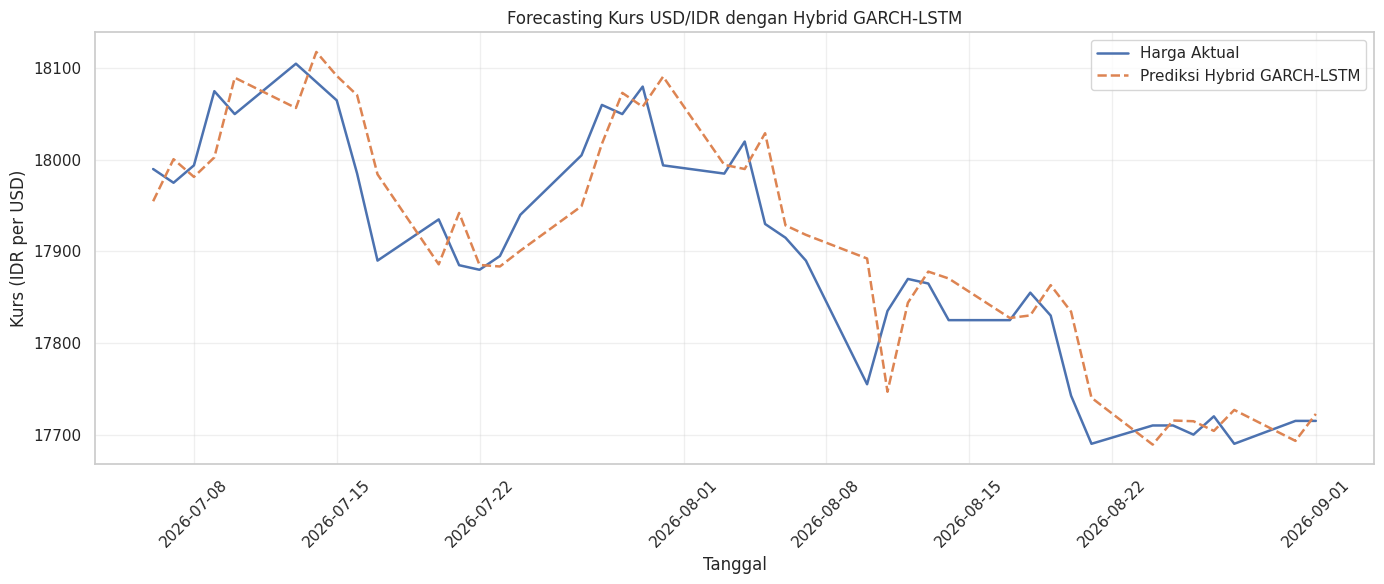

In [60]:
# ============================================
# 10C. VISUALISASI FORECASTING HYBRID
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_evaluasi_hybrid["Tanggal"],
    hasil_evaluasi_hybrid["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=1.8
)

plt.plot(
    hasil_evaluasi_hybrid["Tanggal"],
    hasil_evaluasi_hybrid["Prediksi_Harga_Hybrid"],
    label="Prediksi Hybrid GARCH-LSTM",
    linestyle="--",
    linewidth=1.8
)

plt.title(
    "Forecasting Kurs USD/IDR dengan Hybrid GARCH-LSTM"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
# ============================================
# 11A. ESTIMASI MODEL AKHIR AR(1)-GARCH(1,1)
# ============================================

from arch import arch_model
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Parameter
scale_factor = 10.0
lookback = 10
horizon = 7

# Mengambil seluruh log return
data_return_full = data_return.sort_values(
    "Tanggal"
).copy()

r_full = data_return_full["Log_Return"].astype(float)

# Scaling untuk estimasi GARCH
r_full_scaled = r_full * scale_factor

# Estimasi AR(1)-GARCH(1,1)
model_garch_final = arch_model(
    r_full_scaled,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)

hasil_garch_final = model_garch_final.fit(disp="off")

print("HASIL ESTIMASI MODEL AKHIR AR(1)-GARCH(1,1)")
print(hasil_garch_final.summary())

# Mengambil residual dan mengembalikan ke skala log return asli
residual_full = (
    pd.Series(hasil_garch_final.resid)
    .dropna()
    .to_numpy() / scale_factor
)

print("\nJUMLAH RESIDUAL:", len(residual_full))
print("RATA-RATA RESIDUAL:", np.mean(residual_full))
print("STANDAR DEVIASI RESIDUAL:", np.std(residual_full))

HASIL ESTIMASI MODEL AKHIR AR(1)-GARCH(1,1)
                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.004
Mean Model:                        AR   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -3637.00
Distribution:                  Normal   AIC:                           7283.99
Method:            Maximum Likelihood   BIC:                           7310.36
                                        No. Observations:                 1440
Date:                Mon, Nov 09 2026   Df Residuals:                     1438
Time:                        06:55:34   Df Model:                            2
                                  Mean Model                                 
                    coef    std err          t      P>|t|    95.0% Conf. Int.
-----------------------------------------------------------------------------
Const      

In [62]:
# ============================================
# 11B. NORMALISASI RESIDUAL
# ============================================

scaler_resid_final = MinMaxScaler(
    feature_range=(0, 1)
)

residual_scaled = scaler_resid_final.fit_transform(
    residual_full.reshape(-1, 1)
).flatten()

print("HASIL NORMALISASI RESIDUAL")

print("Ukuran residual asli:", residual_full.shape)
print("Ukuran residual normalisasi:", residual_scaled.shape)

print("Nilai minimum:", residual_scaled.min())
print("Nilai maksimum:", residual_scaled.max())


# ============================================
# PEMBENTUKAN SEKUENS RESIDUAL
# ============================================

X_resid_final = []
y_resid_final = []

for i in range(lookback, len(residual_scaled)):

    X_resid_final.append(
        residual_scaled[i-lookback:i]
    )

    y_resid_final.append(
        residual_scaled[i]
    )

X_resid_final = np.array(X_resid_final).reshape(
    -1, lookback, 1
)

y_resid_final = np.array(y_resid_final)

print("\nHASIL PEMBENTUKAN SEKUENS")

print("X:", X_resid_final.shape)
print("y:", y_resid_final.shape)

HASIL NORMALISASI RESIDUAL
Ukuran residual asli: (1440,)
Ukuran residual normalisasi: (1440,)
Nilai minimum: 0.0
Nilai maksimum: 1.0

HASIL PEMBENTUKAN SEKUENS
X: (1430, 10, 1)
y: (1430,)


In [63]:
# ============================================
# 11C. ARSITEKTUR LSTM RESIDUAL
# ============================================

model_lstm_final = Sequential([
    LSTM(
        16,
        input_shape=(lookback, 1)
    ),

    Dropout(0.2),

    Dense(1)
])

model_lstm_final.compile(
    optimizer="adam",
    loss="mse"
)

model_lstm_final.summary()


# ============================================
# PELATIHAN LSTM RESIDUAL
# ============================================

early_stop_final = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_final = model_lstm_final.fit(
    X_resid_final,
    y_resid_final,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_final],
    verbose=1
)

print("\nPELATIHAN LSTM RESIDUAL SELESAI")
print("Epoch aktual:", len(history_final.history["loss"]))
print("Training loss terbaik:",
      min(history_final.history["loss"]))
print("Validation loss terbaik:",
      min(history_final.history["val_loss"]))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0556 - val_loss: 0.0112
Epoch 2/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0151 - val_loss: 0.0104
Epoch 3/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0145 - val_loss: 0.0104
Epoch 4/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0140 - val_loss: 0.0104
Epoch 5/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0135 - val_loss: 0.0103
Epoch 6/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0130 - val_loss: 0.0102
Epoch 7/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0128 - val_loss: 0.0103
Epoch 8/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0125 - val_loss: 0.0104
Epoch 9/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0124 - val_loss: 0.0103
Epoch 10/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0129 - val_loss: 0.0102
Epoch 11/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0122 - val_loss: 0.0102
Epoch 12/100
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0

In [64]:
# ============================================
# 11D. FORECASTING RESIDUAL LSTM
# ============================================

# Mengambil 10 residual terakhir
window_residual = list(
    residual_scaled[-lookback:]
)

prediksi_residual_future = []

for i in range(horizon):

    # Membentuk input LSTM
    X_input = np.array(
        window_residual[-lookback:]
    ).reshape(1, lookback, 1)

    # Prediksi residual dalam skala normalisasi
    pred_scaled = model_lstm_final.predict(
        X_input,
        verbose=0
    )[0, 0]

    # Mengembalikan ke skala residual asli
    pred_residual = scaler_resid_final.inverse_transform(
        np.array([[pred_scaled]])
    )[0, 0]

    prediksi_residual_future.append(pred_residual)

    # Memasukkan prediksi ke sekuens berikutnya
    window_residual.append(pred_scaled)


prediksi_residual_future = np.array(
    prediksi_residual_future
)

print("PREDIKSI RESIDUAL LSTM SELESAI")
print("Jumlah prediksi:", len(prediksi_residual_future))

display(
    pd.DataFrame({
        "Horizon": range(1, horizon + 1),
        "Prediksi_Residual_LSTM": prediksi_residual_future
    }).round(6)
)

PREDIKSI RESIDUAL LSTM SELESAI
Jumlah prediksi: 7


,Horizon,Prediksi_Residual_LSTM
0,1,-0.003058
1,2,-0.002091
2,3,-0.000264
3,4,0.000676
4,5,0.000403
5,6,0.000547
6,7,0.000796


In [65]:
# ============================================
# 11E. FORECASTING AR(1)-GARCH(1,1)
# ============================================

forecast_garch_final = hasil_garch_final.forecast(
    horizon=horizon,
    reindex=False
)

# Prediksi mean dikembalikan ke skala log return asli
prediksi_garch_future = (
    forecast_garch_final.mean.iloc[-1].to_numpy()
    / scale_factor
)

# Prediksi varians dikembalikan ke skala asli
prediksi_varians_future = (
    forecast_garch_final.variance.iloc[-1].to_numpy()
    / (scale_factor ** 2)
)

# Volatilitas
prediksi_volatilitas_future = np.sqrt(
    prediksi_varians_future
)

print("FORECASTING GARCH SELESAI")
print("Jumlah prediksi:", len(prediksi_garch_future))

display(
    pd.DataFrame({
        "Horizon": range(1, horizon + 1),
        "Prediksi_GARCH": prediksi_garch_future,
        "Prediksi_Varians": prediksi_varians_future,
        "Prediksi_Volatilitas": prediksi_volatilitas_future
    }).round(6)
)

FORECASTING GARCH SELESAI
Jumlah prediksi: 7


,Horizon,Prediksi_GARCH,Prediksi_Varians,Prediksi_Volatilitas
0,1,0.016489,0.085005,0.291555
1,2,0.017457,0.085465,0.292344
2,3,0.017514,0.085633,0.292631
3,4,0.017517,0.085798,0.292913
4,5,0.017517,0.085961,0.293191
5,6,0.017517,0.086123,0.293467
6,7,0.017517,0.086283,0.293739


In [66]:
# ============================================
# 11F. PENGGABUNGAN PREDIKSI GARCH-LSTM
# ============================================

alpha = 1.0

prediksi_hybrid_future = (
    prediksi_garch_future
    + alpha * prediksi_residual_future
)

print("PENGGABUNGAN PREDIKSI HYBRID SELESAI")

display(
    pd.DataFrame({
        "Horizon": range(1, horizon + 1),
        "Prediksi_GARCH": prediksi_garch_future,
        "Prediksi_Residual_LSTM": prediksi_residual_future,
        "Prediksi_Hybrid": prediksi_hybrid_future
    }).round(6)
)

PENGGABUNGAN PREDIKSI HYBRID SELESAI


,Horizon,Prediksi_GARCH,Prediksi_Residual_LSTM,Prediksi_Hybrid
0,1,0.016489,-0.003058,0.013431
1,2,0.017457,-0.002091,0.015366
2,3,0.017514,-0.000264,0.017249
3,4,0.017517,0.000676,0.018193
4,5,0.017517,0.000403,0.017920
5,6,0.017517,0.000547,0.018064
6,7,0.017517,0.000796,0.018313


In [67]:
# ============================================
# 11G. KONVERSI LOG RETURN MENJADI HARGA
# ============================================

# Mengambil tanggal dan harga terakhir
data_sorted = data.sort_values(
    "Tanggal"
).reset_index(drop=True)

tanggal_terakhir = data_sorted["Tanggal"].iloc[-1]

harga_terakhir = float(
    data_sorted["Terakhir"].iloc[-1]
)

# Membuat tanggal forecasting
tanggal_future = pd.bdate_range(
    start=tanggal_terakhir + pd.offsets.BDay(1),
    periods=horizon
)

# Menghitung prediksi harga secara rekursif
prediksi_harga_future = []

harga_sebelumnya = harga_terakhir

for r in prediksi_hybrid_future:

    harga_prediksi = (
        harga_sebelumnya * np.exp(r / 100)
    )

    prediksi_harga_future.append(harga_prediksi)

    harga_sebelumnya = harga_prediksi


# Membentuk tabel akhir
tabel_forecast_hybrid = pd.DataFrame({
    "Tanggal": tanggal_future,
    "Horizon": range(1, horizon + 1),
    "Prediksi_Log_Return_GARCH": prediksi_garch_future,
    "Prediksi_Residual_LSTM": prediksi_residual_future,
    "Prediksi_Log_Return_Hybrid": prediksi_hybrid_future,
    "Prediksi_Varians": prediksi_varians_future,
    "Prediksi_Volatilitas": prediksi_volatilitas_future,
    "Prediksi_Harga": prediksi_harga_future
})

print("HASIL FORECASTING HYBRID GARCH-LSTM 7 PERIODE KE DEPAN")

display(tabel_forecast_hybrid.round(6))

HASIL FORECASTING HYBRID GARCH-LSTM 7 PERIODE KE DEPAN


,Tanggal,Horizon,Prediksi_Log_Return_GARCH,Prediksi_Residual_LSTM,Prediksi_Log_Return_Hybrid,Prediksi_Varians,Prediksi_Volatilitas,Prediksi_Harga
0,2026-09-02,1,0.016489,-0.003058,0.013431,0.085005,0.291555,17717.379418
1,2026-09-03,2,0.017457,-0.002091,0.015366,0.085465,0.292344,17720.102105
2,2026-09-04,3,0.017514,-0.000264,0.017249,0.085633,0.292631,17723.158981
3,2026-09-07,4,0.017517,0.000676,0.018193,0.085798,0.292913,17726.383605
4,2026-09-08,5,0.017517,0.000403,0.017920,0.085961,0.293191,17729.560508
5,2026-09-09,6,0.017517,0.000547,0.018064,0.086123,0.293467,17732.763510
6,2026-09-10,7,0.017517,0.000796,0.018313,0.086283,0.293739,17736.011162


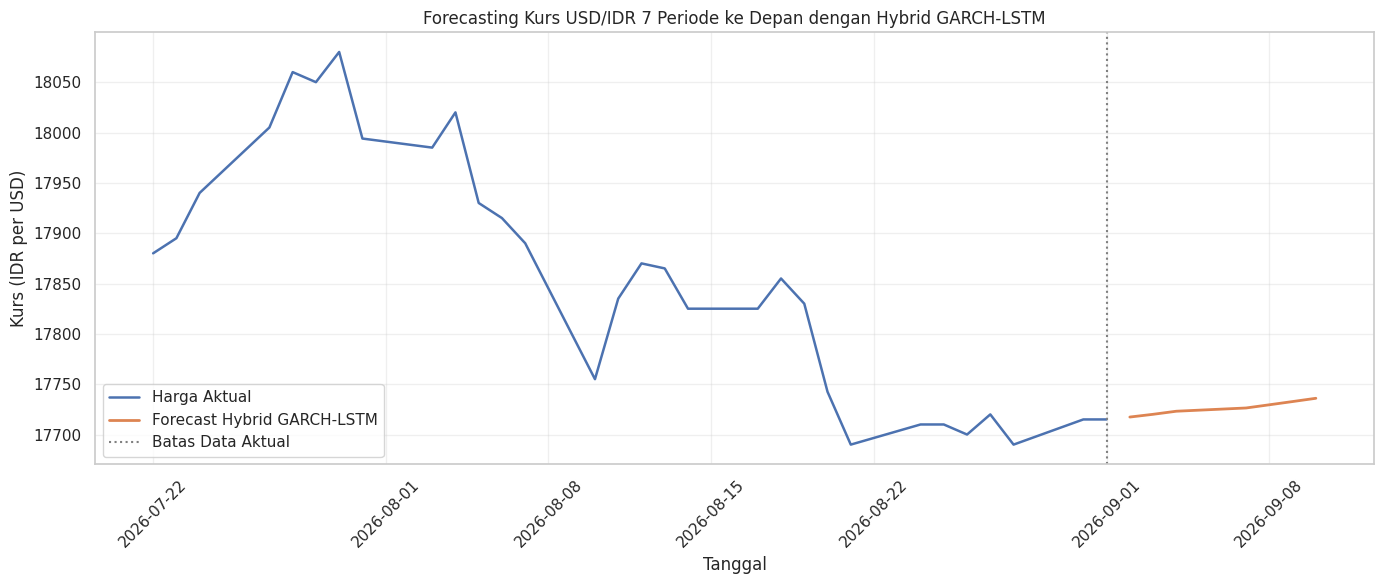

In [68]:
# ============================================
# 11H. VISUALISASI FORECASTING HYBRID
# ============================================

plt.figure(figsize=(14, 6))

# Data aktual 30 observasi terakhir
data_plot = data_sorted.tail(30)

plt.plot(
    data_plot["Tanggal"],
    data_plot["Terakhir"],
    label="Harga Aktual",
    linewidth=1.8
)

# Prediksi hybrid dengan garis utuh
plt.plot(
    tabel_forecast_hybrid["Tanggal"],
    tabel_forecast_hybrid["Prediksi_Harga"],
    linestyle="-",
    linewidth=2,
    label="Forecast Hybrid GARCH-LSTM"
)

# Batas data aktual
plt.axvline(
    x=tanggal_terakhir,
    color="gray",
    linestyle=":",
    label="Batas Data Aktual"
)

plt.title(
    "Forecasting Kurs USD/IDR 7 Periode ke Depan "
    "dengan Hybrid GARCH-LSTM"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **PERBANDINGAN**

In [69]:
# ============================================
# 12A. PENGGABUNGAN HASIL PREDIKSI TIGA MODEL
# ============================================

# 1. Hasil prediksi GARCH
garch_compare = tabel_forecast[
    ["Tanggal", "Harga_Aktual", "Prediksi_Harga"]
].copy()

garch_compare = garch_compare.rename(
    columns={
        "Prediksi_Harga": "Prediksi_GARCH"
    }
)


# 2. Hasil prediksi LSTM
lstm_compare = hasil_lstm[
    ["Tanggal", "Prediksi_Harga"]
].copy()

lstm_compare = lstm_compare.rename(
    columns={
        "Prediksi_Harga": "Prediksi_LSTM"
    }
)


# 3. Hasil prediksi Hybrid
hybrid_compare = hasil_evaluasi_hybrid[
    ["Tanggal", "Prediksi_Harga_Hybrid"]
].copy()


# Menggabungkan ketiga hasil prediksi
perbandingan_prediksi = garch_compare.merge(
    lstm_compare,
    on="Tanggal",
    how="inner"
)

perbandingan_prediksi = perbandingan_prediksi.merge(
    hybrid_compare,
    on="Tanggal",
    how="inner"
)

# Mengurutkan berdasarkan tanggal
perbandingan_prediksi = perbandingan_prediksi.sort_values(
    "Tanggal"
).reset_index(drop=True)

# Memeriksa hasil penggabungan
print("HASIL PENGGABUNGAN PREDIKSI TIGA MODEL")
print("Jumlah observasi:", len(perbandingan_prediksi))

print("\nPemeriksaan missing value:")
print(perbandingan_prediksi.isna().sum())

display(perbandingan_prediksi.round(5))

HASIL PENGGABUNGAN PREDIKSI TIGA MODEL
Jumlah observasi: 42

Pemeriksaan missing value:
Tanggal                  0
Harga_Aktual             0
Prediksi_GARCH           0
Prediksi_LSTM            0
Prediksi_Harga_Hybrid    0
dtype: int64


,Tanggal,Harga_Aktual,Prediksi_GARCH,Prediksi_LSTM,Prediksi_Harga_Hybrid
0,2026-07-06,17990.0,17950.62116,17956.97363,17954.82697
1,2026-07-07,17975.0,17995.57279,17998.51182,18000.73230
2,2026-07-08,17994.0,17977.29093,17982.06905,17981.40671
3,2026-07-09,18075.0,17998.32018,18001.51412,18002.68357
4,2026-07-10,18050.0,18083.03923,18085.34260,18089.71401
5,2026-07-13,18105.0,18051.70913,18057.98936,18056.63169
6,2026-07-14,18085.0,18111.48931,18115.04250,18117.80708
7,2026-07-15,18065.0,18087.01282,18092.93802,18091.76003
8,2026-07-16,17985.0,18067.00928,18071.69743,18070.61259
9,2026-07-17,17890.0,17983.43092,17988.22669,17984.21961


In [70]:
# ============================================
# 12B. EVALUASI PERBANDINGAN TIGA MODEL
# ============================================

aktual = perbandingan_prediksi[
    "Harga_Aktual"
].to_numpy()

prediksi_garch = perbandingan_prediksi[
    "Prediksi_GARCH"
].to_numpy()

prediksi_lstm = perbandingan_prediksi[
    "Prediksi_LSTM"
].to_numpy()

prediksi_hybrid = perbandingan_prediksi[
    "Prediksi_Harga_Hybrid"
].to_numpy()


# Fungsi evaluasi
def hitung_metrik(aktual, prediksi):

    rmse = np.sqrt(
        np.mean((aktual - prediksi) ** 2)
    )

    mae = np.mean(
        np.abs(aktual - prediksi)
    )

    mape = np.mean(
        np.abs((aktual - prediksi) / aktual)
    ) * 100

    return rmse, mae, mape


# Menghitung evaluasi setiap model
hasil_garch = hitung_metrik(aktual, prediksi_garch)
hasil_lstm = hitung_metrik(aktual, prediksi_lstm)
hasil_hybrid = hitung_metrik(aktual, prediksi_hybrid)


# Membentuk tabel perbandingan
tabel_perbandingan = pd.DataFrame({
    "Model": [
        "AR(1)-GARCH(1,1)",
        "LSTM",
        "Hybrid GARCH-LSTM"
    ],
    "RMSE": [
        hasil_garch[0],
        hasil_lstm[0],
        hasil_hybrid[0]
    ],
    "MAE": [
        hasil_garch[1],
        hasil_lstm[1],
        hasil_hybrid[1]
    ],
    "MAPE (%)": [
        hasil_garch[2],
        hasil_lstm[2],
        hasil_hybrid[2]
    ]
})

print("HASIL PERBANDINGAN TIGA MODEL")

display(tabel_perbandingan.round(5))

HASIL PERBANDINGAN TIGA MODEL


,Model,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",50.10417,39.48587,0.22053
1,LSTM,50.68737,40.02068,0.22353
2,Hybrid GARCH-LSTM,50.86609,40.26409,0.22489


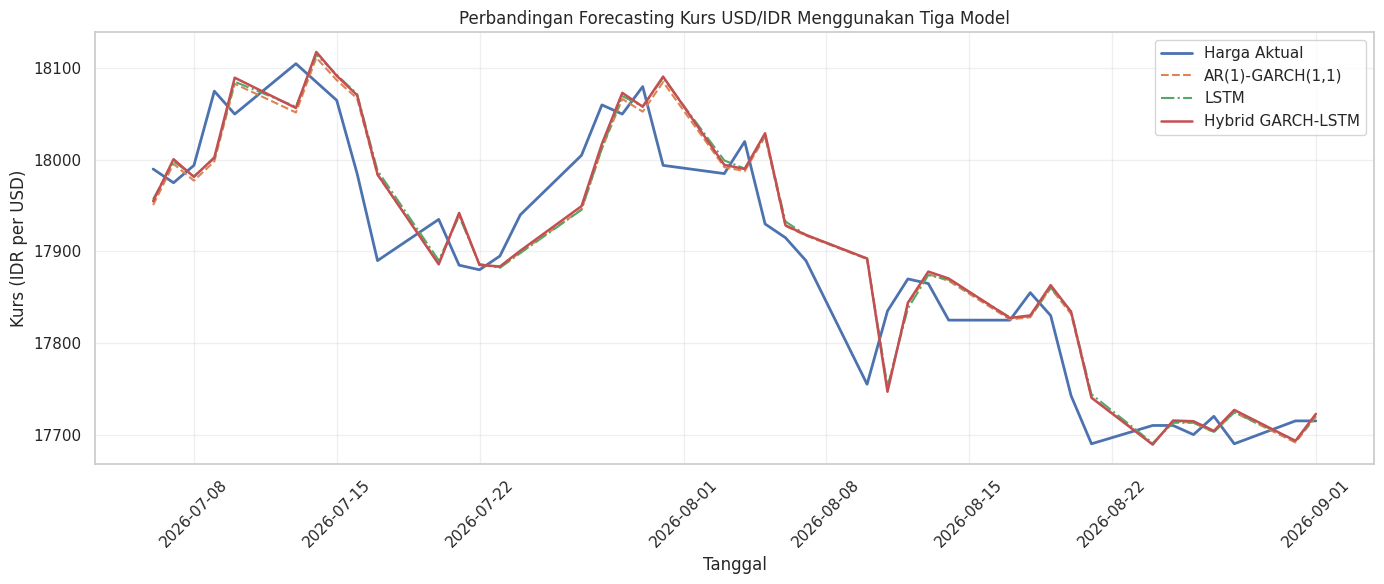

In [71]:
# ============================================
# 12C. VISUALISASI PERBANDINGAN TIGA MODEL
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    perbandingan_prediksi["Tanggal"],
    perbandingan_prediksi["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=2
)

plt.plot(
    perbandingan_prediksi["Tanggal"],
    perbandingan_prediksi["Prediksi_GARCH"],
    label="AR(1)-GARCH(1,1)",
    linewidth=1.5,
    linestyle="--"
)

plt.plot(
    perbandingan_prediksi["Tanggal"],
    perbandingan_prediksi["Prediksi_LSTM"],
    label="LSTM",
    linewidth=1.5,
    linestyle="-."
)

plt.plot(
    perbandingan_prediksi["Tanggal"],
    perbandingan_prediksi["Prediksi_Harga_Hybrid"],
    label="Hybrid GARCH-LSTM",
    linewidth=1.8,
    linestyle="-"
)

plt.title(
    "Perbandingan Forecasting Kurs USD/IDR "
    "Menggunakan Tiga Model"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [72]:
# ============================================
# 13A. PENGGABUNGAN HASIL FORECASTING 3 MODEL
# ============================================

# 1. Forecast GARCH
forecast_garch_compare = tabel_forecast_future[
    ["Tanggal", "Horizon", "Prediksi_Harga"]
].copy()

forecast_garch_compare = forecast_garch_compare.rename(
    columns={
        "Prediksi_Harga": "Forecast_GARCH"
    }
)


# 2. Forecast LSTM
forecast_lstm_compare = hasil_forecast_lstm[
    ["Tanggal", "Horizon", "Prediksi_Harga"]
].copy()

forecast_lstm_compare = forecast_lstm_compare.rename(
    columns={
        "Prediksi_Harga": "Forecast_LSTM"
    }
)


# 3. Forecast Hybrid GARCH-LSTM
forecast_hybrid_compare = tabel_forecast_hybrid[
    ["Tanggal", "Horizon", "Prediksi_Harga"]
].copy()

forecast_hybrid_compare = forecast_hybrid_compare.rename(
    columns={
        "Prediksi_Harga": "Forecast_Hybrid"
    }
)


# Menggabungkan ketiga hasil forecasting
perbandingan_forecast = forecast_garch_compare.merge(
    forecast_lstm_compare[
        ["Tanggal", "Forecast_LSTM"]
    ],
    on="Tanggal",
    how="inner"
)

perbandingan_forecast = perbandingan_forecast.merge(
    forecast_hybrid_compare[
        ["Tanggal", "Forecast_Hybrid"]
    ],
    on="Tanggal",
    how="inner"
)

# Mengurutkan berdasarkan tanggal
perbandingan_forecast = perbandingan_forecast.sort_values(
    "Tanggal"
).reset_index(drop=True)


# Pemeriksaan hasil penggabungan
print("PERBANDINGAN FORECASTING TIGA MODEL")

print("Jumlah periode:", len(perbandingan_forecast))

print("\nPemeriksaan missing value:")
print(perbandingan_forecast.isna().sum())

display(perbandingan_forecast.round(4))

PERBANDINGAN FORECASTING TIGA MODEL
Jumlah periode: 7

Pemeriksaan missing value:
Tanggal            0
Horizon            0
Forecast_GARCH     0
Forecast_LSTM      0
Forecast_Hybrid    0
dtype: int64


,Tanggal,Horizon,Forecast_GARCH,Forecast_LSTM,Forecast_Hybrid
0,2026-09-02,1,17717.9212,17718.9364,17717.3794
1,2026-09-03,2,17721.0145,17723.1811,17720.1021
2,2026-09-04,3,17724.1183,17727.6496,17723.1590
3,2026-09-07,4,17727.2233,17732.2259,17726.3836
4,2026-09-08,5,17730.3289,17736.8233,17729.5605
5,2026-09-09,6,17733.4350,17741.4586,17732.7635
6,2026-09-10,7,17736.5416,17746.1257,17736.0112


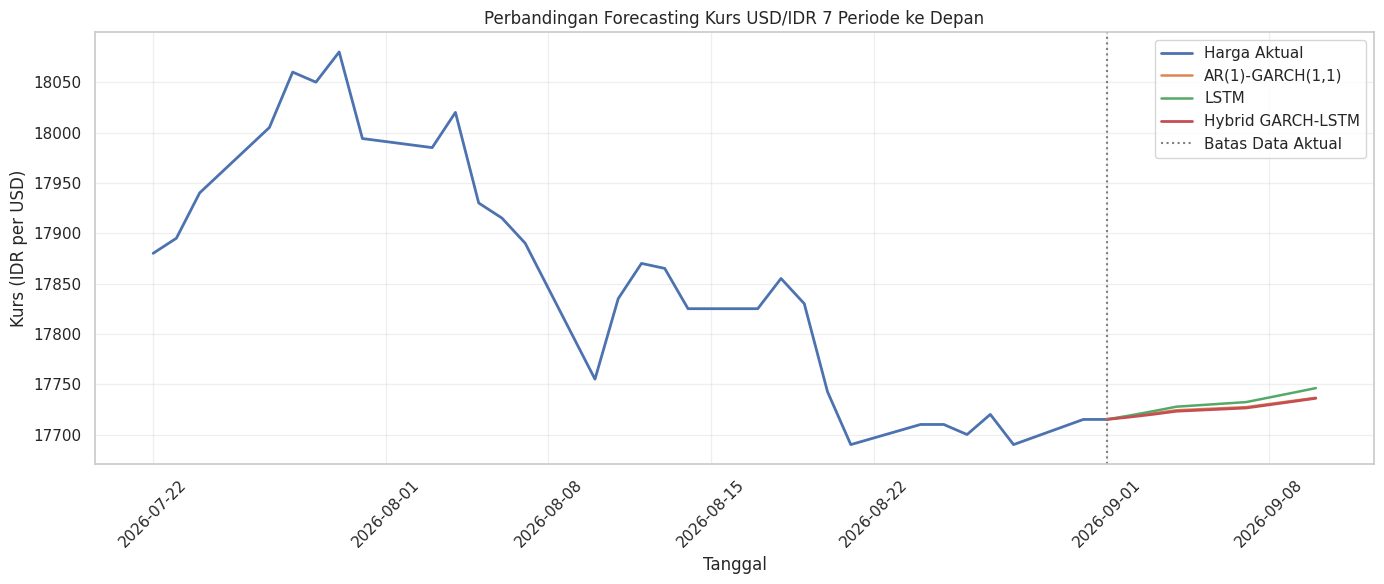

In [73]:
# ============================================
# 13B. VISUALISASI PERBANDINGAN FORECASTING
# ============================================

plt.figure(figsize=(14, 6))

# Data aktual 30 observasi terakhir
data_plot = data.sort_values(
    "Tanggal"
).tail(30)

plt.plot(
    data_plot["Tanggal"],
    data_plot["Terakhir"],
    label="Harga Aktual",
    linewidth=2
)

# Tanggal dan harga aktual terakhir
tanggal_terakhir = pd.to_datetime(
    data["Tanggal"].iloc[-1]
)

harga_terakhir = float(
    data["Terakhir"].iloc[-1]
)

# Menggabungkan titik awal dengan tanggal forecasting
tanggal_garis = pd.concat([
    pd.Series([tanggal_terakhir]),
    perbandingan_forecast["Tanggal"]
])


# Forecast GARCH
harga_garch = np.concatenate([
    [harga_terakhir],
    perbandingan_forecast["Forecast_GARCH"].to_numpy()
])

plt.plot(
    tanggal_garis,
    harga_garch,
    linestyle="-",
    linewidth=1.8,
    label="AR(1)-GARCH(1,1)"
)


# Forecast LSTM
harga_lstm = np.concatenate([
    [harga_terakhir],
    perbandingan_forecast["Forecast_LSTM"].to_numpy()
])

plt.plot(
    tanggal_garis,
    harga_lstm,
    linestyle="-",
    linewidth=1.8,
    label="LSTM"
)


# Forecast Hybrid
harga_hybrid = np.concatenate([
    [harga_terakhir],
    perbandingan_forecast["Forecast_Hybrid"].to_numpy()
])

plt.plot(
    tanggal_garis,
    harga_hybrid,
    linestyle="-",
    linewidth=2,
    label="Hybrid GARCH-LSTM"
)


# Batas data aktual dan forecasting
plt.axvline(
    x=tanggal_terakhir,
    color="gray",
    linestyle=":",
    label="Batas Data Aktual"
)

plt.title(
    "Perbandingan Forecasting Kurs USD/IDR "
    "7 Periode ke Depan"
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()